## Importación de librerías necesarias para el procesamiento de datos

In [ ]:
# ============================================================
# IMPORTACIÓN DE LIBRERÍAS
# ============================================================

import os
import re
import random
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.model_selection import train_test_split

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Conv1D,
    MaxPooling1D,
    LSTM,
    Dense,
    Dropout
)



import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)
# Importar librerías para visualización de datos y métricas de evaluación
import seaborn as sns                    # Visualizaciones estadísticas elegantes
from time import time

In [ ]:
# ============================================================
# REPRODUCIBILIDAD DEL EXPERIMENTO
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    pass

print("✅ Semilla fijada:", SEED)

✅ Semilla fijada: 42


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Carga de Datasets

In [ ]:
# ============================================================
# PARSER OTIDS V2
# Compatible con registros DLC = 0 sin payload
# ============================================================

import os
import re
import gc
import pandas as pd

folder = "/content/drive/MyDrive/Datasets"

files = [
    "Attack_free_dataset.txt",
    "DoS_attack_dataset.txt",
    "Fuzzy_attack_dataset.txt",
    "Impersonation_attack_dataset.txt"
]

# Verificar archivos
print("Archivos encontrados:")

for file_name in files:
    file_path = os.path.join(folder, file_name)

    if not os.path.isfile(file_path):
        raise FileNotFoundError(
            f"No se encontró: {file_path}"
        )

    print("✅", file_name)


# ============================================================
# REGEX V2
# Payload opcional cuando DLC = 0
# ============================================================

pattern = re.compile(
    r"Timestamp:\s+([\d.]+)\s+"
    r"ID:\s+([0-9A-Fa-f]+\s+[0-9]{3})\s+"
    r"DLC:\s+(\d+)"
    r"(?:\s+(.*))?$"
)


# ============================================================
# EXTRAER REGISTROS
# ============================================================

all_data = []

print("\n================ CARGA DE DATASETS ================")

for file_name in files:

    file_path = os.path.join(folder, file_name)

    count = 0

    print(f"\nLeyendo: {file_name}")

    with open(
        file_path,
        "r",
        encoding="latin-1",
        errors="ignore"
    ) as f:

        for line in f:

            match = pattern.search(line.strip())

            if match:

                timestamp = match.group(1)
                can_id = match.group(2)
                dlc = match.group(3)
                data = match.group(4)

                if data is None:
                    data = ""

                all_data.append({
                    "file": file_name,
                    "timestamp": float(timestamp),
                    "id": can_id,
                    "dlc": int(dlc),
                    "data": data.strip()
                })

                count += 1

    print(f"Registros extraídos: {count:,}")


# ============================================================
# DATAFRAME
# ============================================================

df_all = pd.DataFrame(
    all_data,
    columns=[
        "file",
        "timestamp",
        "id",
        "dlc",
        "data"
    ]
)

del all_data
gc.collect()


print("\n================ RESULTADO PARSER V2 ================")

print("Dimensión df_all:", df_all.shape)

print("\nRegistros por archivo:")
print(df_all["file"].value_counts())

print("\nRegistros DLC = 0:")
print(f"{(df_all['dlc'] == 0).sum():,}")

Archivos encontrados:
✅ Attack_free_dataset.txt
✅ DoS_attack_dataset.txt
✅ Fuzzy_attack_dataset.txt
✅ Impersonation_attack_dataset.txt

================ CARGA DE DATASETS ================

Leyendo: Attack_free_dataset.txt
Registros extraídos: 2,369,398

Leyendo: DoS_attack_dataset.txt
Registros extraídos: 656,579

Leyendo: Fuzzy_attack_dataset.txt
Registros extraídos: 591,990

Leyendo: Impersonation_attack_dataset.txt
Registros extraídos: 995,472

================ RESULTADO PARSER V2 ================
Dimensión df_all: (4613439, 5)

Registros por archivo:
file
Attack_free_dataset.txt             2369398
Impersonation_attack_dataset.txt     995472
DoS_attack_dataset.txt               656579
Fuzzy_attack_dataset.txt             591990
Name: count, dtype: int64

Registros DLC = 0:
123,754


In [ ]:
# ============================================================
# VALIDACIÓN CAN V2
# Compatible con DLC = 0
# ============================================================

import re
import pandas as pd


def is_valid_can_record(row):
    """
    Validación conjunta de DLC y payload.

    Reglas:
    - DLC debe estar entre 0 y 8.
    - DLC = 0 implica payload vacío válido.
    - DLC > 0 requiere exactamente DLC bytes.
    - Cada byte debe ser hexadecimal válido (00-FF).
    """

    # --------------------------------------------------------
    # DLC
    # --------------------------------------------------------
    try:
        dlc = int(row["dlc"])
    except (ValueError, TypeError):
        return False

    if not 0 <= dlc <= 8:
        return False

    # --------------------------------------------------------
    # Payload
    # --------------------------------------------------------
    data = row["data"]

    if pd.isna(data):
        data_str = ""
    else:
        data_str = str(data).strip()

    # --------------------------------------------------------
    # DLC = 0
    # Payload vacío es válido
    # --------------------------------------------------------
    if dlc == 0:
        return data_str == ""

    # --------------------------------------------------------
    # DLC > 0
    # Debe existir payload
    # --------------------------------------------------------
    if data_str == "":
        return False

    parts = data_str.split()

    # Número de bytes debe coincidir con DLC
    if len(parts) != dlc:
        return False

    # --------------------------------------------------------
    # Validación hexadecimal byte a byte
    # --------------------------------------------------------
    for part in parts:

        if re.fullmatch(
            r"[0-9A-Fa-f]{1,2}",
            part
        ) is None:
            return False

        try:
            value = int(part, 16)
        except ValueError:
            return False

        if not 0 <= value <= 255:
            return False

    return True


# ============================================================
# APLICAR VALIDACIÓN
# ============================================================

print(
    "Registros antes de validación:",
    f"{len(df_all):,}"
)

valid_can_mask = df_all.apply(
    is_valid_can_record,
    axis=1
)

invalid_can = (
    df_all.loc[~valid_can_mask]
    .copy()
)

df_clean = (
    df_all.loc[valid_can_mask]
    .copy()
    .reset_index(drop=True)
)


# ============================================================
# RESULTADOS
# ============================================================

print("\n==============================================")
print("VALIDACIÓN CAN V2")
print("==============================================")

print(
    "Registros válidos:",
    f"{len(df_clean):,}"
)

print(
    "Registros inválidos:",
    f"{len(invalid_can):,}"
)

print("\nInválidos por archivo:")

if len(invalid_can) > 0:
    print(
        invalid_can["file"].value_counts()
    )
else:
    print("Ninguno")


print("\nDistribución final:")
print(
    df_clean["file"].value_counts()
)


# ============================================================
# DLC = 0
# ============================================================

print("\n==============================================")
print("COMPROBACIÓN DLC = 0")
print("==============================================")

print(
    "DLC = 0 antes:",
    f"{(df_all['dlc'] == 0).sum():,}"
)

print(
    "DLC = 0 después:",
    f"{(df_clean['dlc'] == 0).sum():,}"
)


# ============================================================
# ASSERTS DE SEGURIDAD
# ============================================================

assert len(df_all) == 4613439
assert len(df_clean) == 4613437
assert len(invalid_can) == 2

assert (
    (df_clean["dlc"] == 0).sum()
    == 123754
)

print(
    "\n✅ df_clean V2 reconstruido correctamente."
)

Registros antes de validación: 4,613,439

VALIDACIÓN CAN V2
Registros válidos: 4,613,437
Registros inválidos: 2

Inválidos por archivo:
file
Fuzzy_attack_dataset.txt    2
Name: count, dtype: int64

Distribución final:
file
Attack_free_dataset.txt             2369398
Impersonation_attack_dataset.txt     995472
DoS_attack_dataset.txt               656579
Fuzzy_attack_dataset.txt             591988
Name: count, dtype: int64

COMPROBACIÓN DLC = 0
DLC = 0 antes: 123,754
DLC = 0 después: 123,754

✅ df_clean V2 reconstruido correctamente.


In [ ]:
# ============================================================
# TEMPORAL SPLIT BY OTIDS SOURCE FILE
# 64% TRAIN / 16% VALIDATION / 20% TEMPORAL TEST
# ============================================================

import numpy as np
import pandas as pd

TRAIN_RATIO = 0.64
VAL_RATIO   = 0.16
TEST_RATIO  = 0.20

temporal_train_parts = []
temporal_val_parts = []
temporal_test_parts = []


print("=" * 75)
print("TEMPORAL SPLIT BY SOURCE FILE")
print("=" * 75)


for file_name in df_clean["file"].unique():

    df_file = (
        df_clean.loc[
            df_clean["file"] == file_name
        ]
        .sort_values(
            by="timestamp",
            kind="mergesort"
        )
        .reset_index(drop=True)
    )

    n = len(df_file)

    train_end = int(
        np.floor(n * TRAIN_RATIO)
    )

    val_end = int(
        np.floor(
            n * (TRAIN_RATIO + VAL_RATIO)
        )
    )

    df_train_file = (
        df_file.iloc[:train_end]
        .copy()
    )

    df_val_file = (
        df_file.iloc[
            train_end:val_end
        ]
        .copy()
    )

    df_test_file = (
        df_file.iloc[
            val_end:
        ]
        .copy()
    )


    temporal_train_parts.append(
        df_train_file
    )

    temporal_val_parts.append(
        df_val_file
    )

    temporal_test_parts.append(
        df_test_file
    )


    print(
        f"\n{file_name}"
    )

    print(
        f"Total:      {n:,}"
    )

    print(
        f"Train:      {len(df_train_file):,}"
    )

    print(
        f"Validation: {len(df_val_file):,}"
    )

    print(
        f"Test:       {len(df_test_file):,}"
    )

    print(
        f"Train time: "
        f"{df_train_file['timestamp'].min():.6f}"
        f" → "
        f"{df_train_file['timestamp'].max():.6f}"
    )

    print(
        f"Val time:   "
        f"{df_val_file['timestamp'].min():.6f}"
        f" → "
        f"{df_val_file['timestamp'].max():.6f}"
    )

    print(
        f"Test time:  "
        f"{df_test_file['timestamp'].min():.6f}"
        f" → "
        f"{df_test_file['timestamp'].max():.6f}"
    )


df_temporal_train = (
    pd.concat(
        temporal_train_parts,
        ignore_index=True
    )
)

df_temporal_val = (
    pd.concat(
        temporal_val_parts,
        ignore_index=True
    )
)

df_temporal_test = (
    pd.concat(
        temporal_test_parts,
        ignore_index=True
    )
)


print("\n" + "=" * 75)
print("GLOBAL TEMPORAL SPLIT")
print("=" * 75)

print(
    "Train messages:",
    f"{len(df_temporal_train):,}"
)

print(
    "Validation messages:",
    f"{len(df_temporal_val):,}"
)

print(
    "Temporal Test messages:",
    f"{len(df_temporal_test):,}"
)

print(
    "Total:",
    f"{len(df_temporal_train) + len(df_temporal_val) + len(df_temporal_test):,}"
)


assert (
    len(df_temporal_train)
    + len(df_temporal_val)
    + len(df_temporal_test)
    == len(df_clean)
)

print(
    "\n✅ Temporal split completed without message loss."
)

TEMPORAL SPLIT BY SOURCE FILE

Attack_free_dataset.txt
Total:      2,369,398
Train:      1,516,414
Validation: 379,104
Test:       473,880
Train time: 0.000000 → 664.051065
Val time:   664.051299 → 830.066854
Test time:  830.067624 → 1037.590316

DoS_attack_dataset.txt
Total:      656,579
Train:      420,210
Validation: 105,053
Test:       131,316
Train time: 0.000000 → 211.507716
Val time:   211.507964 → 246.215613
Test time:  246.215856 → 306.296857

Fuzzy_attack_dataset.txt
Total:      591,988
Train:      378,872
Validation: 94,718
Test:       118,398
Train time: 0.000000 → 220.693332
Val time:   220.694362 → 262.353942
Test time:  262.354902 → 347.331739

Impersonation_attack_dataset.txt
Total:      995,472
Train:      637,102
Validation: 159,275
Test:       199,095
Train time: 1481192898.075465 → 1481193209.021469
Val time:   1481193209.022040 → 1481193286.096923
Test time:  1481193286.097159 → 1481193380.725113

GLOBAL TEMPORAL SPLIT
Train messages: 2,952,598
Validation messages:

In [ ]:
# ============================================================
# TEMPORAL WINDOW CONSTRUCTION
# 20 messages x 10 features
#
# FEATURES:
# CAN ID + DLC + DATA0...DATA7
#
# IMPORTANT:
# Windows are constructed independently inside
# Train / Validation / Temporal Test.
# ============================================================

import numpy as np


WINDOW_SIZE = 20

FILE_ORDER = [
    "Attack_free_dataset.txt",
    "DoS_attack_dataset.txt",
    "Fuzzy_attack_dataset.txt",
    "Impersonation_attack_dataset.txt"
]

LABEL_MAP = {
    "Attack_free_dataset.txt": 0,
    "DoS_attack_dataset.txt": 1,
    "Fuzzy_attack_dataset.txt": 2,
    "Impersonation_attack_dataset.txt": 3
}


# ============================================================
# AUXILIARY FUNCTIONS
# ============================================================

def convert_can_id_temporal(value):
    """
    Converts the first hexadecimal CAN-ID token
    into its decimal representation.
    """
    first_token = str(value).strip().split()[0]
    return int(first_token, 16)


def expand_payload_temporal(data_str):
    """
    Converts payload to 8 decimal bytes.
    DLC=0 / empty payload -> eight zeros.
    """

    data_str = str(data_str).strip()

    values = np.zeros(
        8,
        dtype=np.float32
    )

    if data_str != "":
        parts = data_str.split()

        for i, part in enumerate(parts[:8]):
            values[i] = int(part, 16)

    return values


# ============================================================
# BUILD WINDOWS FOR ONE TEMPORAL PARTITION
# ============================================================

def build_temporal_windows(
    df_partition,
    partition_name
):

    X_parts = []
    y_parts = []
    ts_parts = []

    total_remainder = 0

    print("\n" + "=" * 75)
    print(partition_name)
    print("=" * 75)

    for file_name in FILE_ORDER:

        df_file = (
            df_partition.loc[
                df_partition["file"] == file_name
            ]
            .sort_values(
                "timestamp",
                kind="mergesort"
            )
            .reset_index(drop=True)
        )

        n_messages = len(df_file)

        n_windows = (
            n_messages // WINDOW_SIZE
        )

        n_used = (
            n_windows * WINDOW_SIZE
        )

        remainder = (
            n_messages - n_used
        )

        total_remainder += remainder


        # ----------------------------------------------------
        # CAN ID
        # ----------------------------------------------------

        can_id_array = (
            df_file["id"]
            .apply(convert_can_id_temporal)
            .to_numpy(
                dtype=np.float32
            )
        )


        # ----------------------------------------------------
        # DLC
        # ----------------------------------------------------

        dlc_array = (
            df_file["dlc"]
            .to_numpy(
                dtype=np.float32
            )
        )


        # ----------------------------------------------------
        # PAYLOAD DATA0...DATA7
        # ----------------------------------------------------

        payload_array = np.stack(
            df_file["data"]
            .apply(expand_payload_temporal)
            .to_numpy()
        ).astype(np.float32)


        # ----------------------------------------------------
        # 10 FEATURES
        # ----------------------------------------------------

        features_file = np.column_stack([
            can_id_array,
            dlc_array,
            payload_array
        ]).astype(np.float32)


        # Keep only complete windows
        features_file = (
            features_file[:n_used]
        )

        timestamps_file = (
            df_file["timestamp"]
            .to_numpy()[:n_used]
        )


        # ----------------------------------------------------
        # RESHAPE
        # ----------------------------------------------------

        X_file = features_file.reshape(
            n_windows,
            WINDOW_SIZE,
            10
        )

        y_file = np.full(
            n_windows,
            LABEL_MAP[file_name],
            dtype=np.int32
        )

        # timestamp of first message of each window
        ts_file = timestamps_file[
            ::WINDOW_SIZE
        ]


        X_parts.append(X_file)
        y_parts.append(y_file)
        ts_parts.append(ts_file)


        print(
            f"{file_name}: "
            f"{n_messages:,} messages -> "
            f"{n_windows:,} windows | "
            f"remainder = {remainder}"
        )


    X_partition = np.concatenate(
        X_parts,
        axis=0
    )

    y_partition = np.concatenate(
        y_parts,
        axis=0
    )

    ts_partition = np.concatenate(
        ts_parts,
        axis=0
    )


    print("\n----------------------------------------------")

    print(
        "X:",
        X_partition.shape
    )

    print(
        "y:",
        y_partition.shape
    )

    print(
        "ts:",
        ts_partition.shape
    )

    print(
        "Residual messages:",
        total_remainder
    )


    assert X_partition.shape[1:] == (
        20,
        10
    )

    assert len(X_partition) == len(y_partition)

    assert len(X_partition) == len(ts_partition)


    return (
        X_partition,
        y_partition,
        ts_partition
    )

In [ ]:
# ============================================================
# BUILD ALL TEMPORAL WINDOWS
# ============================================================

X_temporal_train_raw, y_temporal_train, ts_temporal_train = (
    build_temporal_windows(
        df_temporal_train,
        "TEMPORAL TRAIN"
    )
)

X_temporal_val_raw, y_temporal_val, ts_temporal_val = (
    build_temporal_windows(
        df_temporal_val,
        "TEMPORAL VALIDATION"
    )
)

X_temporal_test_raw, y_temporal_test, ts_temporal_test = (
    build_temporal_windows(
        df_temporal_test,
        "TEMPORAL TEST"
    )
)


TEMPORAL TRAIN
Attack_free_dataset.txt: 1,516,414 messages -> 75,820 windows | remainder = 14
DoS_attack_dataset.txt: 420,210 messages -> 21,010 windows | remainder = 10
Fuzzy_attack_dataset.txt: 378,872 messages -> 18,943 windows | remainder = 12
Impersonation_attack_dataset.txt: 637,102 messages -> 31,855 windows | remainder = 2

----------------------------------------------
X: (147628, 20, 10)
y: (147628,)
ts: (147628,)
Residual messages: 38

TEMPORAL VALIDATION
Attack_free_dataset.txt: 379,104 messages -> 18,955 windows | remainder = 4
DoS_attack_dataset.txt: 105,053 messages -> 5,252 windows | remainder = 13
Fuzzy_attack_dataset.txt: 94,718 messages -> 4,735 windows | remainder = 18
Impersonation_attack_dataset.txt: 159,275 messages -> 7,963 windows | remainder = 15

----------------------------------------------
X: (36905, 20, 10)
y: (36905,)
ts: (36905,)
Residual messages: 50

TEMPORAL TEST
Attack_free_dataset.txt: 473,880 messages -> 23,694 windows | remainder = 0
DoS_attack_

In [ ]:
# ============================================================
# TEMPORAL MIN-MAX NORMALIZATION
# FIT EXCLUSIVELY ON TEMPORAL TRAIN
# ============================================================

from sklearn.preprocessing import MinMaxScaler

scaler_temporal = MinMaxScaler()

N_FEATURES = 10


# ============================================================
# FIT ONLY TEMPORAL TRAIN
# ============================================================

scaler_temporal.fit(
    X_temporal_train_raw.reshape(
        -1,
        N_FEATURES
    )
)


# ============================================================
# TRANSFORM
# ============================================================

X_temporal_train = (
    scaler_temporal
    .transform(
        X_temporal_train_raw.reshape(
            -1,
            N_FEATURES
        )
    )
    .reshape(
        X_temporal_train_raw.shape
    )
    .astype(np.float32)
)


X_temporal_val = (
    scaler_temporal
    .transform(
        X_temporal_val_raw.reshape(
            -1,
            N_FEATURES
        )
    )
    .reshape(
        X_temporal_val_raw.shape
    )
    .astype(np.float32)
)


X_temporal_test = (
    scaler_temporal
    .transform(
        X_temporal_test_raw.reshape(
            -1,
            N_FEATURES
        )
    )
    .reshape(
        X_temporal_test_raw.shape
    )
    .astype(np.float32)
)


print("\n==============================================")
print("TEMPORAL NORMALIZATION")
print("==============================================")

print(
    "Train:",
    X_temporal_train.shape
)

print(
    "Validation:",
    X_temporal_val.shape
)

print(
    "Temporal Test:",
    X_temporal_test.shape
)

print(
    "\n✅ MinMaxScaler fitted exclusively "
    "on Temporal Train."
)

print(
    "✅ Temporal Validation and Test "
    "were transformed only."
)


TEMPORAL NORMALIZATION
Train: (147628, 20, 10)
Validation: (36905, 20, 10)
Temporal Test: (46132, 20, 10)

✅ MinMaxScaler fitted exclusively on Temporal Train.
✅ Temporal Validation and Test were transformed only.


**Reconstruir V3-C temporal desde cero**

In [ ]:
# ============================================================
# FROZEN CNN-LSTM V3-C — TEMPORAL ROBUSTNESS
# NEW WEIGHTS, SAME FROZEN ARCHITECTURE
# ============================================================

import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Conv1D,
    BatchNormalization,
    Activation,
    MaxPooling1D,
    SpatialDropout1D,
    LSTM,
    Dropout,
    Dense
)

SEED = 42

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)

try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    pass


# ============================================================
# FROZEN V3-C ARCHITECTURE
# ============================================================

model_v3c_temporal = Sequential([

    Input(shape=(20, 10)),

    Conv1D(
        filters=64,
        kernel_size=3,
        padding="same",
        use_bias=False
    ),

    BatchNormalization(),
    Activation("relu"),

    Conv1D(
        filters=128,
        kernel_size=3,
        padding="same",
        use_bias=False
    ),

    BatchNormalization(),
    Activation("relu"),

    MaxPooling1D(
        pool_size=2
    ),

    SpatialDropout1D(
        rate=0.10
    ),

    LSTM(
        units=32,
        return_sequences=False
    ),

    Dropout(
        rate=0.20
    ),

    Dense(
        units=32,
        activation="relu"
    ),

    Dropout(
        rate=0.10
    ),

    Dense(
        units=4,
        activation="softmax"
    )
])


model_v3c_temporal.summary()

# Verificación estricta:
assert model_v3c_temporal.count_params() == 49060

print(
    "\n✅ Frozen V3-C architecture reproduced "
    "with 49,060 parameters."
)

print(
    "✅ Weights initialized from scratch."
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 20, 64)         │         1,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 20, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 20, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 20, 128)        │        24,576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 20, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 20, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 10, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d               │ (None, 10, 128)        │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 32)             │        20,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 49,060 (191.64 KB)

 Trainable params: 48,676 (190.14 KB)

 Non-trainable params: 384 (1.50 KB)


✅ Frozen V3-C architecture reproduced with 49,060 parameters.
✅ Weights initialized from scratch.


**Compilar con los mismos hiperparámetros congelados**

In [ ]:
# ============================================================
# TEMPORAL V3-C — COMPILATION
# SAME FROZEN TRAINING PROTOCOL
# ============================================================

optimizer_temporal = tf.keras.optimizers.AdamW(
    learning_rate=3e-4,
    weight_decay=1e-4
)

model_v3c_temporal.compile(
    optimizer=optimizer_temporal,
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


early_stopping_temporal = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True,
    verbose=1
)


reduce_lr_temporal = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)


print("✅ Temporal V3-C compiled.")

✅ Temporal V3-C compiled.


**Entrenar únicamente con Temporal Train + Validation**

In [ ]:
# ============================================================
# TRAIN FROZEN V3-C ON TEMPORAL PARTITIONS
# TEMPORAL TEST IS NOT USED DURING TRAINING
# ============================================================

from time import perf_counter

EPOCHS_MAX = 30
BATCH_SIZE = 64

start_temporal = perf_counter()

history_v3c_temporal = model_v3c_temporal.fit(

    X_temporal_train,
    y_temporal_train,

    validation_data=(
        X_temporal_val,
        y_temporal_val
    ),

    epochs=EPOCHS_MAX,
    batch_size=BATCH_SIZE,

    callbacks=[
        early_stopping_temporal,
        reduce_lr_temporal
    ],

    verbose=1
)

temporal_training_time = (
    perf_counter() - start_temporal
)


print("\n==============================================")
print("FROZEN V3-C — TEMPORAL TRAINING")
print("==============================================")

print(
    f"Training Time: "
    f"{temporal_training_time:.4f} s"
)

print(
    "Epochs executed:",
    len(history_v3c_temporal.history["loss"])
)

print(
    "\n✅ Temporal Test has not been used."
)

Epoch 1/30
2307/2307 ━━━━━━━━━━━━━━━━━━━━ 59s 24ms/step - accuracy: 0.9543 - loss: 0.1258 - val_accuracy: 0.9873 - val_loss: 0.0353 - learning_rate: 3.0000e-04
Epoch 2/30
2307/2307 ━━━━━━━━━━━━━━━━━━━━ 79s 23ms/step - accuracy: 0.9978 - loss: 0.0077 - val_accuracy: 0.9947 - val_loss: 0.0224 - learning_rate: 3.0000e-04
Epoch 3/30
2307/2307 ━━━━━━━━━━━━━━━━━━━━ 54s 23ms/step - accuracy: 0.9987 - loss: 0.0039 - val_accuracy: 0.9986 - val_loss: 0.0040 - learning_rate: 3.0000e-04
Epoch 4/30
2307/2307 ━━━━━━━━━━━━━━━━━━━━ 54s 23ms/step - accuracy: 0.9994 - loss: 0.0024 - val_accuracy: 0.9985 - val_loss: 0.0052 - learning_rate: 3.0000e-04
Epoch 5/30
2307/2307 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.9994 - loss: 0.0018
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0001500000071246177.
2307/2307 ━━━━━━━━━━━━━━━━━━━━ 82s 23ms/step - accuracy: 0.9995 - loss: 0.0019 - val_accuracy: 0.9940 - val_loss: 0.0275 - learning_rate: 3.0000e-04
Epoch 6/30
2307/2307 ━━━━━━━━━━━━━━━━━━━━ 80s 

**Antes de tocar Temporal Test, verifica la mejor época**

In [ ]:
# ============================================================
# TEMPORAL TRAINING SUMMARY
# ============================================================

import numpy as np

best_epoch = (
    np.argmin(
        history_v3c_temporal.history["val_loss"]
    )
    + 1
)

best_val_loss = min(
    history_v3c_temporal.history["val_loss"]
)

best_val_accuracy = (
    history_v3c_temporal.history[
        "val_accuracy"
    ][
        best_epoch - 1
    ]
)


print("==============================================")
print("TEMPORAL DEVELOPMENT SUMMARY")
print("==============================================")

print(
    "Best epoch:",
    best_epoch
)

print(
    f"Best validation loss: "
    f"{best_val_loss:.10f}"
)

print(
    f"Validation accuracy at best epoch: "
    f"{best_val_accuracy*100:.6f}%"
)

print(
    "\n✅ Model weights correspond to the "
    "best validation loss because "
    "restore_best_weights=True."
)

TEMPORAL DEVELOPMENT SUMMARY
Best epoch: 9
Best validation loss: 0.0013376753
Validation accuracy at best epoch: 99.962068%

✅ Model weights correspond to the best validation loss because restore_best_weights=True.


**Luego sí: una sola evaluación sobre Temporal Test**

In [ ]:
# ============================================================
# FINAL TEMPORAL ROBUSTNESS EVALUATION
# FROZEN CNN-LSTM V3-C
# ============================================================

import numpy as np
from time import perf_counter

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)


# Warm-up fuera del cronometraje
_ = model_v3c_temporal.predict(
    X_temporal_test[:64],
    batch_size=64,
    verbose=0
)


# ============================================================
# ONE FINAL TEMPORAL TEST INFERENCE
# ============================================================

start_inference = perf_counter()

temporal_prob = model_v3c_temporal.predict(
    X_temporal_test,
    batch_size=64,
    verbose=0
)

temporal_inference_time = (
    perf_counter() - start_inference
)

temporal_pred = np.argmax(
    temporal_prob,
    axis=1
)


# ============================================================
# METRICS
# ============================================================

temporal_accuracy = accuracy_score(
    y_temporal_test,
    temporal_pred
)

temporal_macro_precision = precision_score(
    y_temporal_test,
    temporal_pred,
    average="macro",
    zero_division=0
)

temporal_macro_recall = recall_score(
    y_temporal_test,
    temporal_pred,
    average="macro",
    zero_division=0
)

temporal_macro_f1 = f1_score(
    y_temporal_test,
    temporal_pred,
    average="macro",
    zero_division=0
)

temporal_weighted_f1 = f1_score(
    y_temporal_test,
    temporal_pred,
    average="weighted",
    zero_division=0
)

temporal_errors = int(
    np.sum(
        y_temporal_test != temporal_pred
    )
)

temporal_correct = (
    len(y_temporal_test)
    - temporal_errors
)

latency_ms = (
    temporal_inference_time
    / len(y_temporal_test)
    * 1000
)

throughput = (
    len(y_temporal_test)
    / temporal_inference_time
)


# ============================================================
# RESULTS
# ============================================================

print("\n==============================================")
print("V3-C — TEMPORAL ROBUSTNESS RESULTS")
print("==============================================")

print(
    f"Temporal Test sequences: "
    f"{len(y_temporal_test):,}"
)

print(
    f"Correct predictions:     "
    f"{temporal_correct:,}"
)

print(
    f"Misclassifications:      "
    f"{temporal_errors:,}"
)

print("\n----------------------------------------------")

print(
    f"Accuracy:        "
    f"{temporal_accuracy*100:.6f}%"
)

print(
    f"Macro Precision: "
    f"{temporal_macro_precision*100:.6f}%"
)

print(
    f"Macro Recall:    "
    f"{temporal_macro_recall*100:.6f}%"
)

print(
    f"Macro F1:        "
    f"{temporal_macro_f1*100:.6f}%"
)

print(
    f"Weighted F1:     "
    f"{temporal_weighted_f1*100:.6f}%"
)


print("\n==============================================")
print("COMPUTATIONAL PERFORMANCE")
print("==============================================")

print(
    f"Training Time:  "
    f"{temporal_training_time:.4f} s"
)

print(
    f"Inference Time: "
    f"{temporal_inference_time:.4f} s"
)

print(
    f"Latency:        "
    f"{latency_ms:.6f} ms/sequence"
)

print(
    f"Throughput:     "
    f"{throughput:.2f} sequences/s"
)


print("\n==============================================")
print("CLASSIFICATION REPORT")
print("==============================================")

print(
    classification_report(
        y_temporal_test,
        temporal_pred,
        digits=6,
        zero_division=0
    )
)


temporal_cm = confusion_matrix(
    y_temporal_test,
    temporal_pred
)

print("\n==============================================")
print("CONFUSION MATRIX")
print("==============================================")

print(
    temporal_cm
)


V3-C — TEMPORAL ROBUSTNESS RESULTS
Temporal Test sequences: 46,132
Correct predictions:     46,118
Misclassifications:      14

----------------------------------------------
Accuracy:        99.969652%
Macro Precision: 99.973893%
Macro Recall:    99.957524%
Macro F1:        99.965706%
Weighted F1:     99.969649%

COMPUTATIONAL PERFORMANCE
Training Time:  871.4027 s
Inference Time: 4.7130 s
Latency:        0.102164 ms/sequence
Throughput:     9788.21 sequences/s

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0   0.999662  1.000000  0.999831     23694
           1   0.999695  0.999543  0.999619      6565
           2   1.000000  0.999662  0.999831      5919
           3   0.999598  0.999096  0.999347      9954

    accuracy                       0.999697     46132
   macro avg   0.999739  0.999575  0.999657     46132
weighted avg   0.999697  0.999697  0.999696     46132


CONFUSION MATRIX
[[23694     0     0     0]
 [    0  6562     0     3]
 [

**Entrena Random Forest exactamente con el Temporal Train**

In [ ]:
# ============================================================
# RANDOM FOREST — TEMPORAL ROBUSTNESS EVALUATION
#
# SAME TEMPORAL TRAIN AND TEMPORAL TEST AS CNN-LSTM V3-C
# ============================================================

import numpy as np

from time import perf_counter

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)


SEED = 42


# ============================================================
# FLATTEN TEMPORAL WINDOWS
# 20 x 10 = 200 features
# ============================================================

X_temporal_train_rf = (
    X_temporal_train
    .reshape(
        X_temporal_train.shape[0],
        -1
    )
)

X_temporal_test_rf = (
    X_temporal_test
    .reshape(
        X_temporal_test.shape[0],
        -1
    )
)


print("==============================================")
print("RANDOM FOREST TEMPORAL DATA")
print("==============================================")

print(
    "Training:",
    X_temporal_train_rf.shape
)

print(
    "Temporal Test:",
    X_temporal_test_rf.shape
)

assert X_temporal_train_rf.shape == (
    147628,
    200
)

assert X_temporal_test_rf.shape == (
    46132,
    200
)


# ============================================================
# RANDOM FOREST
# SAME CONFIGURATION AS PREVIOUS EXPERIMENT
# ============================================================

rf_temporal = RandomForestClassifier(
    n_estimators=100,
    random_state=SEED,
    n_jobs=-1
)


# ============================================================
# TRAINING
# ============================================================

start_rf_train = perf_counter()

rf_temporal.fit(
    X_temporal_train_rf,
    y_temporal_train
)

rf_temporal_training_time = (
    perf_counter()
    - start_rf_train
)


# ============================================================
# WARM-UP
# ============================================================

_ = rf_temporal.predict(
    X_temporal_test_rf[:64]
)


# ============================================================
# TEMPORAL TEST INFERENCE
# ============================================================

start_rf_inference = perf_counter()

rf_temporal_pred = rf_temporal.predict(
    X_temporal_test_rf
)

rf_temporal_inference_time = (
    perf_counter()
    - start_rf_inference
)


# ============================================================
# METRICS
# ============================================================

rf_temporal_accuracy = accuracy_score(
    y_temporal_test,
    rf_temporal_pred
)

rf_temporal_macro_precision = precision_score(
    y_temporal_test,
    rf_temporal_pred,
    average="macro",
    zero_division=0
)

rf_temporal_macro_recall = recall_score(
    y_temporal_test,
    rf_temporal_pred,
    average="macro",
    zero_division=0
)

rf_temporal_macro_f1 = f1_score(
    y_temporal_test,
    rf_temporal_pred,
    average="macro",
    zero_division=0
)

rf_temporal_weighted_f1 = f1_score(
    y_temporal_test,
    rf_temporal_pred,
    average="weighted",
    zero_division=0
)

rf_temporal_errors = int(
    np.sum(
        y_temporal_test != rf_temporal_pred
    )
)

rf_temporal_correct = (
    len(y_temporal_test)
    - rf_temporal_errors
)

rf_latency_ms = (
    rf_temporal_inference_time
    / len(y_temporal_test)
    * 1000
)

rf_throughput = (
    len(y_temporal_test)
    / rf_temporal_inference_time
)


# ============================================================
# RESULTS
# ============================================================

print("\n==============================================")
print("RANDOM FOREST — TEMPORAL TEST RESULTS")
print("==============================================")

print(
    f"Temporal Test sequences: "
    f"{len(y_temporal_test):,}"
)

print(
    f"Correct predictions:     "
    f"{rf_temporal_correct:,}"
)

print(
    f"Misclassifications:      "
    f"{rf_temporal_errors:,}"
)

print("\n----------------------------------------------")

print(
    f"Accuracy:        "
    f"{rf_temporal_accuracy*100:.6f}%"
)

print(
    f"Macro Precision: "
    f"{rf_temporal_macro_precision*100:.6f}%"
)

print(
    f"Macro Recall:    "
    f"{rf_temporal_macro_recall*100:.6f}%"
)

print(
    f"Macro F1:        "
    f"{rf_temporal_macro_f1*100:.6f}%"
)

print(
    f"Weighted F1:     "
    f"{rf_temporal_weighted_f1*100:.6f}%"
)


print("\n==============================================")
print("COMPUTATIONAL PERFORMANCE")
print("==============================================")

print(
    f"Training Time:  "
    f"{rf_temporal_training_time:.4f} s"
)

print(
    f"Inference Time: "
    f"{rf_temporal_inference_time:.4f} s"
)

print(
    f"Latency:        "
    f"{rf_latency_ms:.6f} ms/sequence"
)

print(
    f"Throughput:     "
    f"{rf_throughput:.2f} sequences/s"
)


# ============================================================
# REPORT
# ============================================================

print("\n==============================================")
print("CLASSIFICATION REPORT")
print("==============================================")

print(
    classification_report(
        y_temporal_test,
        rf_temporal_pred,
        digits=6,
        zero_division=0
    )
)


rf_temporal_cm = confusion_matrix(
    y_temporal_test,
    rf_temporal_pred
)

print("\n==============================================")
print("CONFUSION MATRIX")
print("==============================================")

print(
    rf_temporal_cm
)

RANDOM FOREST TEMPORAL DATA
Training: (147628, 200)
Temporal Test: (46132, 200)

RANDOM FOREST — TEMPORAL TEST RESULTS
Temporal Test sequences: 46,132
Correct predictions:     46,070
Misclassifications:      62

----------------------------------------------
Accuracy:        99.865603%
Macro Precision: 99.931579%
Macro Recall:    99.841275%
Macro F1:        99.886158%
Weighted F1:     99.865491%

COMPUTATIONAL PERFORMANCE
Training Time:  116.0139 s
Inference Time: 0.7295 s
Latency:        0.015813 ms/sequence
Throughput:     63239.60 sequences/s

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0   0.997432  1.000000  0.998714     23694
           1   1.000000  0.999848  0.999924      6565
           2   0.999831  0.999831  0.999831      5919
           3   1.000000  0.993972  0.996977      9954

    accuracy                       0.998656     46132
   macro avg   0.999316  0.998413  0.998862     46132
weighted avg   0.998659  0.998656  0.998655  

**ADDITIONAL CLASSICAL BASELINES — TEMPORAL EVALUATION**

In [ ]:
# ============================================================
# ADDITIONAL CLASSICAL BASELINES — TEMPORAL EVALUATION
#
# Gaussian Naive Bayes
# Logistic Regression
# Linear SVM
# KNN
#
# SAME TEMPORAL TRAIN AND TEMPORAL TEST AS CNN-LSTM
# ============================================================

import numpy as np
import pandas as pd

from time import perf_counter

from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)


# ============================================================
# SAFETY CHECKS
# Reuse the EXACT flattened temporal matrices already created
# for Random Forest
# ============================================================

assert X_temporal_train_rf.shape == (147628, 200)
assert X_temporal_test_rf.shape == (46132, 200)

assert len(y_temporal_train) == 147628
assert len(y_temporal_test) == 46132

print("==============================================")
print("TEMPORAL CLASSICAL BASELINES — DATA CHECK")
print("==============================================")

print("Training:", X_temporal_train_rf.shape)
print("Temporal Test:", X_temporal_test_rf.shape)

print(
    "\n✅ Same chronological training and test "
    "partitions used by Random Forest."
)

print(
    "✅ No new split performed."
)

print(
    "✅ No scaler refitted."
)

TEMPORAL CLASSICAL BASELINES — DATA CHECK
Training: (147628, 200)
Temporal Test: (46132, 200)

✅ Same chronological training and test partitions used by Random Forest.
✅ No new split performed.
✅ No scaler refitted.


In [ ]:
# ============================================================
# COMMON TEMPORAL BASELINE EVALUATION FUNCTION
# ============================================================

def evaluate_temporal_classifier(
    model,
    model_name,
    X_train,
    y_train,
    X_test,
    y_test
):

    print("\n" + "=" * 70)
    print(model_name)
    print("=" * 70)

    # --------------------------------------------------------
    # TRAINING
    # --------------------------------------------------------

    start_train = perf_counter()

    model.fit(
        X_train,
        y_train
    )

    training_time = (
        perf_counter()
        - start_train
    )


    # --------------------------------------------------------
    # WARM-UP
    # Excluded from inference timing
    # --------------------------------------------------------

    _ = model.predict(
        X_test[:64]
    )


    # --------------------------------------------------------
    # TEMPORAL TEST INFERENCE
    # --------------------------------------------------------

    start_inference = perf_counter()

    y_pred = model.predict(
        X_test
    )

    inference_time = (
        perf_counter()
        - start_inference
    )


    # --------------------------------------------------------
    # METRICS
    # --------------------------------------------------------

    accuracy = accuracy_score(
        y_test,
        y_pred
    )

    macro_precision = precision_score(
        y_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    macro_recall = recall_score(
        y_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    macro_f1 = f1_score(
        y_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    weighted_f1 = f1_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    errors = int(
        np.sum(
            y_test != y_pred
        )
    )

    correct = int(
        np.sum(
            y_test == y_pred
        )
    )

    latency_ms = (
        inference_time
        / len(y_test)
        * 1000
    )

    throughput = (
        len(y_test)
        / inference_time
    )

    cm = confusion_matrix(
        y_test,
        y_pred
    )


    # --------------------------------------------------------
    # OUTPUT
    # --------------------------------------------------------

    print(
        f"Temporal Test sequences: "
        f"{len(y_test):,}"
    )

    print(
        f"Correct predictions:     "
        f"{correct:,}"
    )

    print(
        f"Misclassifications:      "
        f"{errors:,}"
    )

    print("\n----------------------------------------------")

    print(
        f"Accuracy:        "
        f"{accuracy*100:.6f}%"
    )

    print(
        f"Macro Precision: "
        f"{macro_precision*100:.6f}%"
    )

    print(
        f"Macro Recall:    "
        f"{macro_recall*100:.6f}%"
    )

    print(
        f"Macro F1:        "
        f"{macro_f1*100:.6f}%"
    )

    print(
        f"Weighted F1:     "
        f"{weighted_f1*100:.6f}%"
    )

    print("\n==============================================")
    print("COMPUTATIONAL PERFORMANCE")
    print("==============================================")

    print(
        f"Training Time:  "
        f"{training_time:.6f} s"
    )

    print(
        f"Inference Time: "
        f"{inference_time:.6f} s"
    )

    print(
        f"Latency:        "
        f"{latency_ms:.6f} ms/sequence"
    )

    print(
        f"Throughput:     "
        f"{throughput:.2f} sequences/s"
    )

    print("\n==============================================")
    print("CONFUSION MATRIX")
    print("==============================================")

    print(cm)

    print("\n==============================================")
    print("CLASSIFICATION REPORT")
    print("==============================================")

    print(
        classification_report(
            y_test,
            y_pred,
            digits=6,
            zero_division=0
        )
    )


    results = {

        "Model":
            model_name,

        "Test Sequences":
            len(y_test),

        "Accuracy (%)":
            accuracy * 100,

        "Macro Precision (%)":
            macro_precision * 100,

        "Macro Recall (%)":
            macro_recall * 100,

        "Macro F1 (%)":
            macro_f1 * 100,

        "Weighted F1 (%)":
            weighted_f1 * 100,

        "Errors":
            errors,

        "Training Time (s)":
            training_time,

        "Inference Time (s)":
            inference_time
    }

    return (
        model,
        y_pred,
        cm,
        results
    )

In [ ]:
# ============================================================
# GAUSSIAN NAIVE BAYES — TEMPORAL
# ============================================================

nb_temporal = GaussianNB()

(
    nb_temporal,
    nb_temporal_pred,
    nb_temporal_cm,
    nb_temporal_results
) = evaluate_temporal_classifier(

    model=nb_temporal,

    model_name=
        "Gaussian Naive Bayes",

    X_train=
        X_temporal_train_rf,

    y_train=
        y_temporal_train,

    X_test=
        X_temporal_test_rf,

    y_test=
        y_temporal_test
)


Gaussian Naive Bayes
Temporal Test sequences: 46,132
Correct predictions:     40,744
Misclassifications:      5,388

----------------------------------------------
Accuracy:        88.320472%
Macro Precision: 90.575002%
Macro Recall:    89.504216%
Macro F1:        89.718410%
Weighted F1:     88.671855%

COMPUTATIONAL PERFORMANCE
Training Time:  0.250227 s
Inference Time: 0.375205 s
Latency:        0.008133 ms/sequence
Throughput:     122951.41 sequences/s

CONFUSION MATRIX
[[20585     0     8  3101]
 [  150  6298     0   117]
 [  252     0  5250   417]
 [ 1339     3     1  8611]]

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0   0.922019  0.868785  0.894611     23694
           1   0.999524  0.959330  0.979014      6565
           2   0.998289  0.886974  0.939345      5919
           3   0.703168  0.865079  0.775766      9954

    accuracy                       0.883205     46132
   macro avg   0.905750  0.895042  0.897184     46132
weighted 

In [ ]:
# ============================================================
# LOGISTIC REGRESSION — TEMPORAL
# ============================================================

lr_temporal = LogisticRegression(
    max_iter=1000
)

(
    lr_temporal,
    lr_temporal_pred,
    lr_temporal_cm,
    lr_temporal_results
) = evaluate_temporal_classifier(

    model=lr_temporal,

    model_name=
        "Logistic Regression",

    X_train=
        X_temporal_train_rf,

    y_train=
        y_temporal_train,

    X_test=
        X_temporal_test_rf,

    y_test=
        y_temporal_test
)


Logistic Regression
Temporal Test sequences: 46,132
Correct predictions:     41,113
Misclassifications:      5,019

----------------------------------------------
Accuracy:        89.120350%
Macro Precision: 90.786492%
Macro Recall:    91.198527%
Macro F1:        90.965971%
Weighted F1:     89.225483%

COMPUTATIONAL PERFORMANCE
Training Time:  59.892947 s
Inference Time: 0.061062 s
Latency:        0.001324 ms/sequence
Throughput:     755495.41 sequences/s

CONFUSION MATRIX
[[20913     3    55  2723]
 [   14  6548     0     3]
 [   72     0  5788    59]
 [ 2066    13    11  7864]]

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0   0.906698  0.882629  0.894502     23694
           1   0.997562  0.997411  0.997486      6565
           2   0.988726  0.977868  0.983267      5919
           3   0.738473  0.790034  0.763384      9954

    accuracy                       0.891204     46132
   macro avg   0.907865  0.911985  0.909660     46132
weighted 

In [ ]:
# ============================================================
# LINEAR SVM — TEMPORAL
# ============================================================

svm_temporal = LinearSVC(
    C=1.0
)

(
    svm_temporal,
    svm_temporal_pred,
    svm_temporal_cm,
    svm_temporal_results
) = evaluate_temporal_classifier(

    model=svm_temporal,

    model_name=
        "Linear SVM",

    X_train=
        X_temporal_train_rf,

    y_train=
        y_temporal_train,

    X_test=
        X_temporal_test_rf,

    y_test=
        y_temporal_test
)


Linear SVM
Temporal Test sequences: 46,132
Correct predictions:     40,900
Misclassifications:      5,232

----------------------------------------------
Accuracy:        88.658632%
Macro Precision: 90.468561%
Macro Recall:    90.503737%
Macro F1:        90.475693%
Weighted F1:     88.731862%

COMPUTATIONAL PERFORMANCE
Training Time:  26.599452 s
Inference Time: 0.043480 s
Latency:        0.000943 ms/sequence
Throughput:     1061001.54 sequences/s

CONFUSION MATRIX
[[20978     2    43  2671]
 [   23  6540     0     2]
 [   95     0  5756    68]
 [ 2290    17    21  7626]]

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0   0.897032  0.885372  0.891164     23694
           1   0.997103  0.996192  0.996647      6565
           2   0.989003  0.972462  0.980663      5919
           3   0.735603  0.766124  0.750554      9954

    accuracy                       0.886586     46132
   macro avg   0.904686  0.905037  0.904757     46132
weighted avg   0.

In [ ]:
# ============================================================
# KNN — TEMPORAL
# ============================================================

knn_temporal = KNeighborsClassifier(
    n_neighbors=5,
    n_jobs=-1
)

(
    knn_temporal,
    knn_temporal_pred,
    knn_temporal_cm,
    knn_temporal_results
) = evaluate_temporal_classifier(

    model=knn_temporal,

    model_name="KNN",

    X_train=X_temporal_train_rf,
    y_train=y_temporal_train,

    X_test=X_temporal_test_rf,
    y_test=y_temporal_test
)


KNN
Temporal Test sequences: 46,132
Correct predictions:     33,901
Misclassifications:      12,231

----------------------------------------------
Accuracy:        73.486950%
Macro Precision: 77.471420%
Macro Recall:    70.368748%
Macro F1:        72.483951%
Weighted F1:     71.557162%

COMPUTATIONAL PERFORMANCE
Training Time:  0.036672 s
Inference Time: 122.599563 s
Latency:        2.657582 ms/sequence
Throughput:     376.28 sequences/s

CONFUSION MATRIX
[[20751    92     0  2851]
 [    3  6562     0     0]
 [ 1103    35  4053   728]
 [ 7373    46     0  2535]]

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0   0.709921  0.875791  0.784181     23694
           1   0.974313  0.999543  0.986767      6565
           2   1.000000  0.684744  0.812876      5919
           3   0.414622  0.254671  0.315534      9954

    accuracy                       0.734870     46132
   macro avg   0.774714  0.703687  0.724840     46132
weighted avg   0.721048  0

In [ ]:
# ============================================================
# CHECK THAT ALL TEMPORAL BASELINE RESULTS EXIST
# ============================================================

variables_to_check = [
    "nb_temporal_results",
    "lr_temporal_results",
    "svm_temporal_results",
    "knn_temporal_results"
]

for var in variables_to_check:
    if var in globals():
        print(f"✅ {var} exists")
    else:
        print(f"❌ {var} NOT FOUND")

✅ nb_temporal_results exists
✅ lr_temporal_results exists
✅ svm_temporal_results exists
✅ knn_temporal_results exists


In [ ]:
# ============================================================
# FINAL TEMPORAL COMPARISON
# CNN-LSTM vs RF vs NB vs LR vs SVM vs KNN
# ============================================================

temporal_all_models_table = pd.DataFrame([

    {
        "Model":
            "Proposed CNN-LSTM",

        "Test Sequences":
            len(y_temporal_test),

        "Accuracy (%)":
            temporal_accuracy * 100,

        "Macro Precision (%)":
            temporal_macro_precision * 100,

        "Macro Recall (%)":
            temporal_macro_recall * 100,

        "Macro F1 (%)":
            temporal_macro_f1 * 100,

        "Weighted F1 (%)":
            temporal_weighted_f1 * 100,

        "Errors":
            temporal_errors,

        "Training Time (s)":
            temporal_training_time,

        "Inference Time (s)":
            temporal_inference_time
    },

    {
        "Model":
            "Random Forest",

        "Test Sequences":
            len(y_temporal_test),

        "Accuracy (%)":
            rf_temporal_accuracy * 100,

        "Macro Precision (%)":
            rf_temporal_macro_precision * 100,

        "Macro Recall (%)":
            rf_temporal_macro_recall * 100,

        "Macro F1 (%)":
            rf_temporal_macro_f1 * 100,

        "Weighted F1 (%)":
            rf_temporal_weighted_f1 * 100,

        "Errors":
            rf_temporal_errors,

        "Training Time (s)":
            rf_temporal_training_time,

        "Inference Time (s)":
            rf_temporal_inference_time
    },

    nb_temporal_results,

    lr_temporal_results,

    svm_temporal_results,

    knn_temporal_results
])


print("\n" + "=" * 120)
print("TEMPORAL CLASSIFICATION PERFORMANCE")
print("=" * 120)

print(
    temporal_all_models_table.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)


TEMPORAL CLASSIFICATION PERFORMANCE
               Model  Test Sequences  Accuracy (%)  Macro Precision (%)  Macro Recall (%)  Macro F1 (%)  Weighted F1 (%)  Errors  Training Time (s)  Inference Time (s)
   Proposed CNN-LSTM           46132     99.969652            99.973893         99.957524     99.965706        99.969649      14         871.402690            4.713019
       Random Forest           46132     99.865603            99.931579         99.841275     99.886158        99.865491      62         116.013877            0.729480
Gaussian Naive Bayes           46132     88.320472            90.575002         89.504216     89.718410        88.671855    5388           0.250227            0.375205
 Logistic Regression           46132     89.120350            90.786492         91.198527     90.965971        89.225483    5019          59.892947            0.061062
          Linear SVM           46132     88.658632            90.468561         90.503737     90.475693        88.731862   

**Después ejecuta McNemar V3-C vs RF**

In [ ]:
# ============================================================
# EXACT McNEMAR TEST
# TEMPORAL V3-C vs TEMPORAL RANDOM FOREST
# ============================================================

import numpy as np
from scipy.stats import binomtest


# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------

assert len(temporal_pred) == len(y_temporal_test)
assert len(rf_temporal_pred) == len(y_temporal_test)


cnn_correct = (
    temporal_pred
    == y_temporal_test
)

rf_correct = (
    rf_temporal_pred
    == y_temporal_test
)


# ============================================================
# PAIRED CONTINGENCY TABLE
# ============================================================

both_correct = int(
    np.sum(
        cnn_correct
        & rf_correct
    )
)

cnn_correct_rf_wrong = int(
    np.sum(
        cnn_correct
        & ~rf_correct
    )
)

cnn_wrong_rf_correct = int(
    np.sum(
        ~cnn_correct
        & rf_correct
    )
)

both_wrong = int(
    np.sum(
        ~cnn_correct
        & ~rf_correct
    )
)


print("\n==============================================")
print("TEMPORAL McNEMAR CONTINGENCY TABLE")
print("==============================================")

print(
    "Both correct:",
    both_correct
)

print(
    "V3-C correct / RF wrong:",
    cnn_correct_rf_wrong
)

print(
    "V3-C wrong / RF correct:",
    cnn_wrong_rf_correct
)

print(
    "Both wrong:",
    both_wrong
)

print(
    "\nTotal:",
    (
        both_correct
        + cnn_correct_rf_wrong
        + cnn_wrong_rf_correct
        + both_wrong
    )
)


# ============================================================
# EXACT McNEMAR
# ============================================================

b = cnn_correct_rf_wrong
c = cnn_wrong_rf_correct

discordant = b + c


if discordant == 0:

    p_value_temporal = 1.0

else:

    p_value_temporal = binomtest(
        k=b,
        n=discordant,
        p=0.5,
        alternative="two-sided"
    ).pvalue


print("\n==============================================")
print("EXACT McNEMAR TEST — TEMPORAL")
print("==============================================")

print(
    f"V3-C correct / RF wrong (b): "
    f"{b}"
)

print(
    f"V3-C wrong / RF correct (c): "
    f"{c}"
)

print(
    f"Discordant pairs: "
    f"{discordant}"
)

print(
    f"Exact p-value: "
    f"{p_value_temporal:.10f}"
)


if p_value_temporal < 0.05:

    if b > c:

        print(
            "\n✅ Statistically significant "
            "difference favoring CNN-LSTM V3-C."
        )

    else:

        print(
            "\n⚠️ Statistically significant "
            "difference favoring Random Forest."
        )

else:

    print(
        "\n✅ No statistically significant "
        "difference between V3-C and Random Forest."
    )


TEMPORAL McNEMAR CONTINGENCY TABLE
Both correct: 46058
V3-C correct / RF wrong: 60
V3-C wrong / RF correct: 12
Both wrong: 2

Total: 46132

EXACT McNEMAR TEST — TEMPORAL
V3-C correct / RF wrong (b): 60
V3-C wrong / RF correct (c): 12
Discordant pairs: 72
Exact p-value: 0.0000000081

✅ Statistically significant difference favoring CNN-LSTM V3-C.


**Guardar formalmente todo el experimento temporal**

In [ ]:
# ============================================================
# SAVE FINAL TEMPORAL EXPERIMENT EVIDENCE
# PROPOSED CNN-LSTM + RF + NB + LR + SVM + KNN
# + EXACT McNEMAR + METRICS
#
# SAME CHRONOLOGICAL HOLD-OUT PROTOCOL
# ============================================================

import os
import json
import joblib
import hashlib
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

from scipy.stats import binomtest


# ============================================================
# 1. OUTPUT DIRECTORY
# ============================================================

FINAL_DIR = (
    "/content/drive/MyDrive/"
    "CAN_IDS_FINAL_EVIDENCE/"
    "TEMPORAL_EXPERIMENT"
)

os.makedirs(
    FINAL_DIR,
    exist_ok=True
)

print("=" * 100)
print("FINAL TEMPORAL EXPERIMENT EVIDENCE")
print("=" * 100)

print("\nSaving to:")
print(FINAL_DIR)


# ============================================================
# 2. SAFETY CHECKS
# ============================================================

# Chronological partitions
assert len(y_temporal_train) == 147628
assert len(y_temporal_val) == 36905
assert len(y_temporal_test) == 46132

# Final compact CNN-LSTM architecture
assert model_v3c_temporal.count_params() == 49060

# Prediction arrays
prediction_sets = {

    "Proposed CNN-LSTM":
        temporal_pred,

    "Random Forest":
        rf_temporal_pred,

    "Gaussian Naive Bayes":
        nb_temporal_pred,

    "Logistic Regression":
        lr_temporal_pred,

    "Linear SVM":
        svm_temporal_pred,

    "KNN":
        knn_temporal_pred
}


for model_name, y_pred in prediction_sets.items():

    assert len(y_pred) == 46132, (
        f"ERROR: {model_name} does not contain "
        f"46,132 Temporal Test predictions."
    )


# Check trained model objects
required_objects = [

    "model_v3c_temporal",
    "rf_temporal",
    "nb_temporal",
    "lr_temporal",
    "svm_temporal",
    "knn_temporal",
    "scaler_temporal"
]


for object_name in required_objects:

    assert object_name in globals(), (
        f"ERROR: required object not found: {object_name}"
    )


print("\n✅ Temporal Train:       147,628 sequences")
print("✅ Temporal Validation:  36,905 sequences")
print("✅ Temporal Test:         46,132 sequences")
print("✅ All six prediction arrays are aligned.")
print("✅ Proposed CNN-LSTM = 49,060 parameters.")
print("✅ No new data split performed.")
print("✅ Temporal scaler not refitted.")


# ============================================================
# 3. METRIC FUNCTION
# Recompute directly from predictions
# ============================================================

def compute_temporal_metrics(
    y_true,
    y_pred
):

    return {

        "accuracy":
            float(
                accuracy_score(
                    y_true,
                    y_pred
                )
            ),

        "macro_precision":
            float(
                precision_score(
                    y_true,
                    y_pred,
                    average="macro",
                    zero_division=0
                )
            ),

        "macro_recall":
            float(
                recall_score(
                    y_true,
                    y_pred,
                    average="macro",
                    zero_division=0
                )
            ),

        "macro_f1":
            float(
                f1_score(
                    y_true,
                    y_pred,
                    average="macro",
                    zero_division=0
                )
            ),

        "weighted_f1":
            float(
                f1_score(
                    y_true,
                    y_pred,
                    average="weighted",
                    zero_division=0
                )
            ),

        "errors":
            int(
                np.sum(
                    y_true != y_pred
                )
            ),

        "correct":
            int(
                np.sum(
                    y_true == y_pred
                )
            )
    }


# ============================================================
# 4. RECOMPUTE METRICS — ALL SIX MODELS
# ============================================================

cnn_temporal_metrics = compute_temporal_metrics(
    y_temporal_test,
    temporal_pred
)

rf_temporal_metrics = compute_temporal_metrics(
    y_temporal_test,
    rf_temporal_pred
)

nb_temporal_metrics = compute_temporal_metrics(
    y_temporal_test,
    nb_temporal_pred
)

lr_temporal_metrics = compute_temporal_metrics(
    y_temporal_test,
    lr_temporal_pred
)

svm_temporal_metrics = compute_temporal_metrics(
    y_temporal_test,
    svm_temporal_pred
)

knn_temporal_metrics = compute_temporal_metrics(
    y_temporal_test,
    knn_temporal_pred
)


# ============================================================
# 5. ADD COMPUTATIONAL PERFORMANCE
# ============================================================

# -------------------------
# Proposed CNN-LSTM
# -------------------------

cnn_temporal_metrics[
    "training_time_seconds"
] = float(
    temporal_training_time
)

cnn_temporal_metrics[
    "inference_time_seconds"
] = float(
    temporal_inference_time
)

cnn_temporal_metrics[
    "parameters"
] = int(
    model_v3c_temporal.count_params()
)


# -------------------------
# Random Forest
# -------------------------

rf_temporal_metrics[
    "training_time_seconds"
] = float(
    rf_temporal_training_time
)

rf_temporal_metrics[
    "inference_time_seconds"
] = float(
    rf_temporal_inference_time
)

rf_temporal_metrics[
    "trees"
] = int(
    len(
        rf_temporal.estimators_
    )
)


# -------------------------
# Gaussian Naive Bayes
# -------------------------

nb_temporal_metrics[
    "training_time_seconds"
] = float(
    nb_temporal_results[
        "Training Time (s)"
    ]
)

nb_temporal_metrics[
    "inference_time_seconds"
] = float(
    nb_temporal_results[
        "Inference Time (s)"
    ]
)


# -------------------------
# Logistic Regression
# -------------------------

lr_temporal_metrics[
    "training_time_seconds"
] = float(
    lr_temporal_results[
        "Training Time (s)"
    ]
)

lr_temporal_metrics[
    "inference_time_seconds"
] = float(
    lr_temporal_results[
        "Inference Time (s)"
    ]
)


# -------------------------
# Linear SVM
# -------------------------

svm_temporal_metrics[
    "training_time_seconds"
] = float(
    svm_temporal_results[
        "Training Time (s)"
    ]
)

svm_temporal_metrics[
    "inference_time_seconds"
] = float(
    svm_temporal_results[
        "Inference Time (s)"
    ]
)


# -------------------------
# KNN
# -------------------------

knn_temporal_metrics[
    "training_time_seconds"
] = float(
    knn_temporal_results[
        "Training Time (s)"
    ]
)

knn_temporal_metrics[
    "inference_time_seconds"
] = float(
    knn_temporal_results[
        "Inference Time (s)"
    ]
)


# ============================================================
# 6. CONFUSION MATRICES
# ============================================================

cnn_temporal_cm = confusion_matrix(
    y_temporal_test,
    temporal_pred
)

rf_temporal_cm = confusion_matrix(
    y_temporal_test,
    rf_temporal_pred
)

nb_temporal_cm = confusion_matrix(
    y_temporal_test,
    nb_temporal_pred
)

lr_temporal_cm = confusion_matrix(
    y_temporal_test,
    lr_temporal_pred
)

svm_temporal_cm = confusion_matrix(
    y_temporal_test,
    svm_temporal_pred
)

knn_temporal_cm = confusion_matrix(
    y_temporal_test,
    knn_temporal_pred
)


confusion_matrices = {

    "proposed_cnn_lstm":
        cnn_temporal_cm,

    "random_forest":
        rf_temporal_cm,

    "gaussian_naive_bayes":
        nb_temporal_cm,

    "logistic_regression":
        lr_temporal_cm,

    "linear_svm":
        svm_temporal_cm,

    "knn":
        knn_temporal_cm
}


# Save individual confusion matrices
for model_name, cm in confusion_matrices.items():

    np.savetxt(

        os.path.join(
            FINAL_DIR,
            f"{model_name}_temporal_confusion_matrix.csv"
        ),

        cm,

        delimiter=",",

        fmt="%d"
    )


# Save together
np.savez_compressed(

    os.path.join(
        FINAL_DIR,
        "all_temporal_confusion_matrices.npz"
    ),

    proposed_cnn_lstm=
        cnn_temporal_cm,

    random_forest=
        rf_temporal_cm,

    gaussian_naive_bayes=
        nb_temporal_cm,

    logistic_regression=
        lr_temporal_cm,

    linear_svm=
        svm_temporal_cm,

    knn=
        knn_temporal_cm
)


# ============================================================
# 7. SAVE ALL TEST PREDICTIONS
# ============================================================

prediction_bundle = {

    "y_true":
        np.asarray(
            y_temporal_test
        ),

    "proposed_cnn_lstm_pred":
        np.asarray(
            temporal_pred
        ),

    "random_forest_pred":
        np.asarray(
            rf_temporal_pred
        ),

    "gaussian_naive_bayes_pred":
        np.asarray(
            nb_temporal_pred
        ),

    "logistic_regression_pred":
        np.asarray(
            lr_temporal_pred
        ),

    "linear_svm_pred":
        np.asarray(
            svm_temporal_pred
        ),

    "knn_pred":
        np.asarray(
            knn_temporal_pred
        )
}


# CNN-LSTM probabilities
if "temporal_prob" in globals():

    assert len(temporal_prob) == 46132

    prediction_bundle[
        "proposed_cnn_lstm_prob"
    ] = np.asarray(
        temporal_prob
    )


# Chronological timestamps
if "ts_temporal_test" in globals():

    assert len(ts_temporal_test) == 46132

    prediction_bundle[
        "temporal_timestamps"
    ] = np.asarray(
        ts_temporal_test
    )


np.savez_compressed(

    os.path.join(
        FINAL_DIR,
        "temporal_test_predictions_all_models.npz"
    ),

    **prediction_bundle
)


# ============================================================
# 8. SAVE TRAINED MODELS AND SCALER
# ============================================================

CNN_MODEL_PATH = os.path.join(
    FINAL_DIR,
    "proposed_cnn_lstm_temporal.keras"
)

RF_MODEL_PATH = os.path.join(
    FINAL_DIR,
    "random_forest_temporal.joblib"
)

NB_MODEL_PATH = os.path.join(
    FINAL_DIR,
    "gaussian_naive_bayes_temporal.joblib"
)

LR_MODEL_PATH = os.path.join(
    FINAL_DIR,
    "logistic_regression_temporal.joblib"
)

SVM_MODEL_PATH = os.path.join(
    FINAL_DIR,
    "linear_svm_temporal.joblib"
)

KNN_MODEL_PATH = os.path.join(
    FINAL_DIR,
    "knn_temporal.joblib"
)

SCALER_PATH = os.path.join(
    FINAL_DIR,
    "minmax_scaler_temporal.joblib"
)


# CNN-LSTM
model_v3c_temporal.save(
    CNN_MODEL_PATH
)


# Random Forest
joblib.dump(
    rf_temporal,
    RF_MODEL_PATH,
    compress=3
)


# Gaussian Naive Bayes
joblib.dump(
    nb_temporal,
    NB_MODEL_PATH,
    compress=3
)


# Logistic Regression
joblib.dump(
    lr_temporal,
    LR_MODEL_PATH,
    compress=3
)


# Linear SVM
joblib.dump(
    svm_temporal,
    SVM_MODEL_PATH,
    compress=3
)


# KNN
joblib.dump(
    knn_temporal,
    KNN_MODEL_PATH,
    compress=3
)


# Temporal scaler
joblib.dump(
    scaler_temporal,
    SCALER_PATH,
    compress=3
)


# ============================================================
# 9. EXACT TWO-SIDED McNEMAR
# Proposed CNN-LSTM vs Random Forest
# ============================================================

cnn_correct = (
    temporal_pred
    == y_temporal_test
)

rf_correct = (
    rf_temporal_pred
    == y_temporal_test
)


both_correct = int(
    np.sum(
        cnn_correct
        & rf_correct
    )
)

cnn_correct_rf_wrong = int(
    np.sum(
        cnn_correct
        & ~rf_correct
    )
)

cnn_wrong_rf_correct = int(
    np.sum(
        ~cnn_correct
        & rf_correct
    )
)

both_wrong = int(
    np.sum(
        ~cnn_correct
        & ~rf_correct
    )
)


discordant_pairs = (
    cnn_correct_rf_wrong
    + cnn_wrong_rf_correct
)


if discordant_pairs == 0:

    exact_p_value = 1.0

else:

    exact_p_value = float(

        binomtest(

            k=cnn_correct_rf_wrong,

            n=discordant_pairs,

            p=0.5,

            alternative="two-sided"

        ).pvalue
    )


if cnn_correct_rf_wrong > cnn_wrong_rf_correct:

    favored_model = (
        "Proposed CNN-LSTM"
    )

elif cnn_wrong_rf_correct > cnn_correct_rf_wrong:

    favored_model = (
        "Random Forest"
    )

else:

    favored_model = (
        "Neither"
    )


temporal_mcnemar = {

    "comparison":
        "Proposed CNN-LSTM vs Random Forest",

    "statistical_test":
        "Exact McNemar via binomial test",

    "alternative":
        "two-sided",

    "null_probability":
        0.5,

    "alpha":
        0.05,

    "both_correct":
        both_correct,

    "cnn_correct_rf_wrong":
        cnn_correct_rf_wrong,

    "cnn_wrong_rf_correct":
        cnn_wrong_rf_correct,

    "both_wrong":
        both_wrong,

    "discordant_pairs":
        discordant_pairs,

    "exact_p_value":
        exact_p_value,

    "significant":
        bool(
            exact_p_value < 0.05
        ),

    "favored_model":
        favored_model
}


# Save McNemar independently
MCNEMAR_PATH = os.path.join(
    FINAL_DIR,
    "temporal_mcnemar_cnn_lstm_vs_rf.json"
)

with open(
    MCNEMAR_PATH,
    "w"
) as f:

    json.dump(
        temporal_mcnemar,
        f,
        indent=4
    )


# ============================================================
# 10. MODEL CONFIGURATIONS
# Read directly from trained objects
# ============================================================

def json_safe(value):

    if isinstance(
        value,
        dict
    ):

        return {
            str(k):
                json_safe(v)
            for k, v
            in value.items()
        }

    if isinstance(
        value,
        (list, tuple)
    ):

        return [
            json_safe(v)
            for v in value
        ]

    if isinstance(
        value,
        np.ndarray
    ):

        return value.tolist()

    if isinstance(
        value,
        (
            np.integer,
            np.floating,
            np.bool_
        )
    ):

        return value.item()

    if value is None or isinstance(
        value,
        (
            str,
            int,
            float,
            bool
        )
    ):

        return value

    return str(value)


model_configurations = {

    "proposed_cnn_lstm": {

        "parameters":
            int(
                model_v3c_temporal.count_params()
            ),

        "optimizer":
            type(
                model_v3c_temporal.optimizer
            ).__name__,

        "loss":
            str(
                model_v3c_temporal.loss
            )
    },

    "random_forest":
        rf_temporal.get_params(
            deep=True
        ),

    "gaussian_naive_bayes":
        nb_temporal.get_params(
            deep=True
        ),

    "logistic_regression":
        lr_temporal.get_params(
            deep=True
        ),

    "linear_svm":
        svm_temporal.get_params(
            deep=True
        ),

    "knn":
        knn_temporal.get_params(
            deep=True
        )
}


CONFIG_PATH = os.path.join(
    FINAL_DIR,
    "temporal_model_configurations.json"
)


with open(
    CONFIG_PATH,
    "w"
) as f:

    json.dump(
        json_safe(
            model_configurations
        ),
        f,
        indent=4
    )


# ============================================================
# 11. COMPLETE EXPERIMENT METRICS
# ============================================================

experiment_metrics = {

    "protocol":
        (
            "Chronological hold-out / "
            "temporal robustness evaluation"
        ),

    "valid_can_messages":
        4613437,

    "window_size":
        20,

    "features_per_message":
        10,

    "temporal_train_sequences":
        int(
            len(
                y_temporal_train
            )
        ),

    "temporal_validation_sequences":
        int(
            len(
                y_temporal_val
            )
        ),

    "temporal_test_sequences":
        int(
            len(
                y_temporal_test
            )
        ),

    "class_mapping": {

        "0":
            "Attack-free",

        "1":
            "DoS",

        "2":
            "Fuzzy",

        "3":
            "Impersonation"
    },

    "models": {

        "proposed_cnn_lstm":
            cnn_temporal_metrics,

        "random_forest":
            rf_temporal_metrics,

        "gaussian_naive_bayes":
            nb_temporal_metrics,

        "logistic_regression":
            lr_temporal_metrics,

        "linear_svm":
            svm_temporal_metrics,

        "knn":
            knn_temporal_metrics
    },

    "mcnemar_cnn_lstm_vs_random_forest":
        temporal_mcnemar,

    "scaler":
        (
            "MinMaxScaler fitted exclusively "
            "on temporal training data"
        ),

    "window_protocol":
        (
            "Non-overlapping 20-message windows "
            "constructed independently within "
            "chronological partitions"
        ),

    "cnn_architecture_frozen_before_temporal_evaluation":
        True,

    "cnn_retrained_from_new_initialization":
        True
}


METRICS_JSON_PATH = os.path.join(
    FINAL_DIR,
    "temporal_experiment_metrics_all_models.json"
)


with open(
    METRICS_JSON_PATH,
    "w"
) as f:

    json.dump(
        json_safe(
            experiment_metrics
        ),
        f,
        indent=4
    )


# ============================================================
# 12. HUMAN-READABLE FINAL METRICS TABLE
# ============================================================

def make_temporal_row(
    model_name,
    metrics
):

    return {

        "Protocol":
            "Chronological hold-out",

        "Model":
            model_name,

        "Test Sequences":
            len(
                y_temporal_test
            ),

        "Accuracy (%)":
            metrics[
                "accuracy"
            ] * 100,

        "Macro Precision (%)":
            metrics[
                "macro_precision"
            ] * 100,

        "Macro Recall (%)":
            metrics[
                "macro_recall"
            ] * 100,

        "Macro F1 (%)":
            metrics[
                "macro_f1"
            ] * 100,

        "Weighted F1 (%)":
            metrics[
                "weighted_f1"
            ] * 100,

        "Errors":
            metrics[
                "errors"
            ],

        "Training Time (s)":
            metrics[
                "training_time_seconds"
            ],

        "Inference Time (s)":
            metrics[
                "inference_time_seconds"
            ]
    }


temporal_all_models_final = pd.DataFrame([

    make_temporal_row(
        "Proposed CNN-LSTM",
        cnn_temporal_metrics
    ),

    make_temporal_row(
        "Random Forest",
        rf_temporal_metrics
    ),

    make_temporal_row(
        "Gaussian Naive Bayes",
        nb_temporal_metrics
    ),

    make_temporal_row(
        "Logistic Regression",
        lr_temporal_metrics
    ),

    make_temporal_row(
        "Linear SVM",
        svm_temporal_metrics
    ),

    make_temporal_row(
        "KNN",
        knn_temporal_metrics
    )
])


METRICS_CSV_PATH = os.path.join(
    FINAL_DIR,
    "temporal_model_comparison_all_models.csv"
)


temporal_all_models_final.to_csv(
    METRICS_CSV_PATH,
    index=False
)


# ============================================================
# 13. REPRODUCIBILITY SHA-256 HASHES
# ============================================================

def sha256_file(path):

    h = hashlib.sha256()

    with open(
        path,
        "rb"
    ) as f:

        for block in iter(
            lambda: f.read(
                1024 * 1024
            ),
            b""
        ):

            h.update(
                block
            )

    return h.hexdigest()


files_to_hash = {

    "Proposed CNN-LSTM":
        CNN_MODEL_PATH,

    "Random Forest":
        RF_MODEL_PATH,

    "Gaussian Naive Bayes":
        NB_MODEL_PATH,

    "Logistic Regression":
        LR_MODEL_PATH,

    "Linear SVM":
        SVM_MODEL_PATH,

    "KNN":
        KNN_MODEL_PATH,

    "Temporal MinMaxScaler":
        SCALER_PATH,

    "Metrics JSON":
        METRICS_JSON_PATH,

    "Metrics CSV":
        METRICS_CSV_PATH,

    "McNemar JSON":
        MCNEMAR_PATH,

    "Model Configurations JSON":
        CONFIG_PATH
}


hash_manifest = {}


for artifact_name, artifact_path in files_to_hash.items():

    if os.path.exists(
        artifact_path
    ):

        hash_manifest[
            artifact_name
        ] = {

            "file":
                os.path.basename(
                    artifact_path
                ),

            "sha256":
                sha256_file(
                    artifact_path
                )
        }


HASH_PATH = os.path.join(
    FINAL_DIR,
    "temporal_sha256_manifest.json"
)


with open(
    HASH_PATH,
    "w"
) as f:

    json.dump(
        hash_manifest,
        f,
        indent=4
    )


# ============================================================
# 14. ARTIFACT MANIFEST
# ============================================================

artifact_manifest = {

    "Proposed CNN-LSTM model":
        CNN_MODEL_PATH,

    "Random Forest model":
        RF_MODEL_PATH,

    "Gaussian Naive Bayes model":
        NB_MODEL_PATH,

    "Logistic Regression model":
        LR_MODEL_PATH,

    "Linear SVM model":
        SVM_MODEL_PATH,

    "KNN model":
        KNN_MODEL_PATH,

    "Temporal MinMaxScaler":
        SCALER_PATH,

    "Predictions":
        os.path.join(
            FINAL_DIR,
            "temporal_test_predictions_all_models.npz"
        ),

    "Confusion matrices":
        os.path.join(
            FINAL_DIR,
            "all_temporal_confusion_matrices.npz"
        ),

    "Metrics CSV":
        METRICS_CSV_PATH,

    "Metrics JSON":
        METRICS_JSON_PATH,

    "Model configurations":
        CONFIG_PATH,

    "McNemar":
        MCNEMAR_PATH,

    "SHA-256 manifest":
        HASH_PATH
}


MANIFEST_PATH = os.path.join(
    FINAL_DIR,
    "temporal_artifact_manifest.json"
)


with open(
    MANIFEST_PATH,
    "w"
) as f:

    json.dump(
        artifact_manifest,
        f,
        indent=4
    )


# ============================================================
# 15. FINAL VERIFICATION
# ============================================================

print("\n" + "=" * 130)
print("FINAL TEMPORAL CLASSIFICATION PERFORMANCE")
print("=" * 130)

print(

    temporal_all_models_final.to_string(

        index=False,

        float_format=lambda x: f"{x:.6f}"
    )
)


print("\n" + "=" * 100)
print("EXACT McNEMAR — PROPOSED CNN-LSTM vs RANDOM FOREST")
print("=" * 100)

print(
    json.dumps(
        temporal_mcnemar,
        indent=4
    )
)


print("\n" + "=" * 100)
print("SAVED ARTIFACTS")
print("=" * 100)


for artifact_name, artifact_path in artifact_manifest.items():

    status = (
        "✅"
        if os.path.exists(
            artifact_path
        )
        else "❌"
    )

    print(
        f"{status} "
        f"{artifact_name}: "
        f"{artifact_path}"
    )


print("\n" + "=" * 100)

print("✅ Proposed CNN-LSTM saved.")
print("✅ Random Forest saved.")
print("✅ Gaussian Naive Bayes saved.")
print("✅ Logistic Regression saved.")
print("✅ Linear SVM saved.")
print("✅ KNN saved.")

print("✅ Temporal MinMaxScaler saved.")

print(
    "✅ Predictions for all six models saved."
)

print(
    "✅ Confusion matrices for all six models saved."
)

print(
    "✅ Performance metrics for all six models saved."
)

print(
    "✅ Actual trained-model configurations saved."
)

print(
    "✅ Exact two-sided McNemar result saved."
)

print(
    "✅ SHA-256 reproducibility hashes generated."
)

print(
    "✅ V3-C removed from final artifact labels."
)

print("=" * 100)

print(
    "FINAL TEMPORAL EVIDENCE PACKAGE COMPLETED."
)

FINAL TEMPORAL EXPERIMENT EVIDENCE

Saving to:
/content/drive/MyDrive/CAN_IDS_FINAL_EVIDENCE/TEMPORAL_EXPERIMENT

✅ Temporal Train:       147,628 sequences
✅ Temporal Validation:  36,905 sequences
✅ Temporal Test:         46,132 sequences
✅ All six prediction arrays are aligned.
✅ Proposed CNN-LSTM = 49,060 parameters.
✅ No new data split performed.
✅ Temporal scaler not refitted.

FINAL TEMPORAL CLASSIFICATION PERFORMANCE
              Protocol                Model  Test Sequences  Accuracy (%)  Macro Precision (%)  Macro Recall (%)  Macro F1 (%)  Weighted F1 (%)  Errors  Training Time (s)  Inference Time (s)
Chronological hold-out    Proposed CNN-LSTM           46132     99.969652            99.973893         99.957524     99.965706        99.969649      14         871.402690            4.713019
Chronological hold-out        Random Forest           46132     99.865603            99.931579         99.841275     99.886158        99.865491      62         116.013877            0.729480


**Añadir hashes SHA-256**

In [ ]:
# ============================================================
# SHA-256 REPRODUCIBILITY MANIFEST
# ============================================================

import hashlib
import os
import json


def sha256_file(path):

    h = hashlib.sha256()

    with open(
        path,
        "rb"
    ) as f:

        for block in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            h.update(block)

    return h.hexdigest()


files_to_hash = {

    "CNN-LSTM V3-C model":
        CNN_MODEL_PATH,

    "Random Forest model":
        RF_MODEL_PATH,

    "Temporal MinMaxScaler":
        SCALER_PATH,

    "Predictions":
        os.path.join(
            FINAL_DIR,
            "temporal_test_predictions.npz"
        ),

    "Metrics":
        os.path.join(
            FINAL_DIR,
            "temporal_experiment_metrics.json"
        )
}


hash_manifest = {}

for name, path in files_to_hash.items():

    hash_manifest[name] = {
        "path": path,
        "sha256": sha256_file(path)
    }


with open(
    os.path.join(
        FINAL_DIR,
        "SHA256_MANIFEST.json"
    ),
    "w"
) as f:

    json.dump(
        hash_manifest,
        f,
        indent=4
    )


print(
    json.dumps(
        hash_manifest,
        indent=4
    )
)

print(
    "\n✅ SHA-256 manifest created."
)

{
    "CNN-LSTM V3-C model": {
        "path": "/content/drive/MyDrive/CAN_IDS_FINAL_EVIDENCE/TEMPORAL_EXPERIMENT/proposed_cnn_lstm_temporal.keras",
        "sha256": "9e0adba213e55a6068ffa77adc7c3cfe87ed5ca77155cbb2481c119492ad04b6"
    },
    "Random Forest model": {
        "path": "/content/drive/MyDrive/CAN_IDS_FINAL_EVIDENCE/TEMPORAL_EXPERIMENT/random_forest_temporal.joblib",
        "sha256": "b0bccc9ba97e0582c7a56adb3c6fa18a1233bab566ed430830f2de2a4ba5d650"
    },
    "Temporal MinMaxScaler": {
        "path": "/content/drive/MyDrive/CAN_IDS_FINAL_EVIDENCE/TEMPORAL_EXPERIMENT/minmax_scaler_temporal.joblib",
        "sha256": "42fb6865ee8a5129d5dadf82b82fcdab787f456860eb684955f2d4f1e8c98eed"
    },
    "Predictions": {
        "path": "/content/drive/MyDrive/CAN_IDS_FINAL_EVIDENCE/TEMPORAL_EXPERIMENT/temporal_test_predictions.npz",
        "sha256": "8f7a6b3cfed9e6e1f6b9c430a15363fc985997aa01a8eb6a3c77cce6f701c200"
    },
    "Metrics": {
        "path": "/content/drive/MyDrive/

**Ahora construir Random Split vs Temporal Split**

In [ ]:
# ============================================================
# FINAL IEEE ACCESS TABLE
# RANDOM SPLIT vs TEMPORAL SPLIT
# ============================================================

import pandas as pd
import os


# ============================================================
# VERIFIED RANDOM-SPLIT V2 RESULTS
# Previously frozen experiment
# ============================================================

random_results = [

    {
        "Evaluation Protocol":
            "Random stratified",

        "Model":
            "CNN-LSTM V2",

        "Test Sequences":
            46134,

        "Accuracy (%)":
            99.952313,

        "Macro Precision (%)":
            99.954710,

        "Macro Recall (%)":
            99.958962,

        "Macro F1 (%)":
            99.956832,

        "Weighted F1 (%)":
            99.952317,

        "Errors":
            22
    },

    {
        "Evaluation Protocol":
            "Random stratified",

        "Model":
            "Random Forest",

        "Test Sequences":
            46134,

        "Accuracy (%)":
            99.978324,

        "Macro Precision (%)":
            99.986284,

        "Macro Recall (%)":
            99.970167,

        "Macro F1 (%)":
            99.978221,

        "Weighted F1 (%)":
            99.978323,

        "Errors":
            10
    }
]


# ============================================================
# TEMPORAL RESULTS
# Computed directly from current saved predictions
# ============================================================

temporal_results = [

    {
        "Evaluation Protocol":
            "Chronological hold-out",

        "Model":
            "CNN-LSTM V3-C",

        "Test Sequences":
            len(y_temporal_test),

        "Accuracy (%)":
            cnn_temporal_metrics[
                "accuracy"
            ] * 100,

        "Macro Precision (%)":
            cnn_temporal_metrics[
                "macro_precision"
            ] * 100,

        "Macro Recall (%)":
            cnn_temporal_metrics[
                "macro_recall"
            ] * 100,

        "Macro F1 (%)":
            cnn_temporal_metrics[
                "macro_f1"
            ] * 100,

        "Weighted F1 (%)":
            cnn_temporal_metrics[
                "weighted_f1"
            ] * 100,

        "Errors":
            cnn_temporal_metrics[
                "errors"
            ]
    },

    {
        "Evaluation Protocol":
            "Chronological hold-out",

        "Model":
            "Random Forest",

        "Test Sequences":
            len(y_temporal_test),

        "Accuracy (%)":
            rf_temporal_metrics[
                "accuracy"
            ] * 100,

        "Macro Precision (%)":
            rf_temporal_metrics[
                "macro_precision"
            ] * 100,

        "Macro Recall (%)":
            rf_temporal_metrics[
                "macro_recall"
            ] * 100,

        "Macro F1 (%)":
            rf_temporal_metrics[
                "macro_f1"
            ] * 100,

        "Weighted F1 (%)":
            rf_temporal_metrics[
                "weighted_f1"
            ] * 100,

        "Errors":
            rf_temporal_metrics[
                "errors"
            ]
    }
]


# ============================================================
# FINAL TABLE
# ============================================================

final_ieee_table = pd.DataFrame(
    random_results
    + temporal_results
)


print("\n")
print("=" * 120)
print("FINAL MODEL PERFORMANCE BY EVALUATION PROTOCOL")
print("=" * 120)

print(
    final_ieee_table.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)


# ============================================================
# SAVE CSV
# ============================================================

FINAL_TABLE_PATH = os.path.join(
    FINAL_DIR,
    "IEEE_Access_Random_vs_Temporal.csv"
)

final_ieee_table.to_csv(
    FINAL_TABLE_PATH,
    index=False
)

print(
    "\n✅ Final IEEE comparison table saved:"
)

print(
    FINAL_TABLE_PATH
)



FINAL MODEL PERFORMANCE BY EVALUATION PROTOCOL
   Evaluation Protocol         Model  Test Sequences  Accuracy (%)  Macro Precision (%)  Macro Recall (%)  Macro F1 (%)  Weighted F1 (%)  Errors
     Random stratified   CNN-LSTM V2           46134     99.952313            99.954710         99.958962     99.956832        99.952317      22
     Random stratified Random Forest           46134     99.978324            99.986284         99.970167     99.978221        99.978323      10
Chronological hold-out CNN-LSTM V3-C           46132     99.969652            99.973893         99.957524     99.965706        99.969649      14
Chronological hold-out Random Forest           46132     99.865603            99.931579         99.841275     99.886158        99.865491      62

✅ Final IEEE comparison table saved:
/content/drive/MyDrive/CAN_IDS_FINAL_EVIDENCE/TEMPORAL_EXPERIMENT/IEEE_Access_Random_vs_Temporal.csv


**Crear la tabla estadística separada**

In [ ]:
# ============================================================
# PAIRED STATISTICAL COMPARISON TABLE
# ============================================================

statistical_table = pd.DataFrame([

    {
        "Evaluation Protocol":
            "Random stratified",

        "CNN model":
            "CNN-LSTM V2",

        "CNN correct / RF wrong":
            8,

        "CNN wrong / RF correct":
            20,

        "Exact McNemar p-value":
            0.0356981382,

        "Significant (alpha=0.05)":
            "Yes",

        "Favored model":
            "Random Forest"
    },

    {
        "Evaluation Protocol":
            "Chronological hold-out",

        "CNN model":
            "CNN-LSTM V3-C",

        "CNN correct / RF wrong":
            temporal_mcnemar[
                "cnn_correct_rf_wrong"
            ],

        "CNN wrong / RF correct":
            temporal_mcnemar[
                "cnn_wrong_rf_correct"
            ],

        "Exact McNemar p-value":
            temporal_mcnemar[
                "exact_p_value"
            ],

        "Significant (alpha=0.05)":
            (
                "Yes"
                if temporal_mcnemar[
                    "significant"
                ]
                else "No"
            ),

        "Favored model":
            temporal_mcnemar[
                "favored_model"
            ]
    }
])


print("\n")
print("=" * 110)
print("PAIRED STATISTICAL COMPARISON")
print("=" * 110)

print(
    statistical_table.to_string(
        index=False
    )
)


statistical_table.to_csv(

    os.path.join(
        FINAL_DIR,
        "IEEE_Access_McNemar_Comparison.csv"
    ),

    index=False
)



PAIRED STATISTICAL COMPARISON
   Evaluation Protocol     CNN model  CNN correct / RF wrong  CNN wrong / RF correct  Exact McNemar p-value Significant (alpha=0.05)     Favored model
     Random stratified   CNN-LSTM V2                       8                      20           3.569814e-02                      Yes     Random Forest
Chronological hold-out CNN-LSTM V3-C                      60                      12           8.055499e-09                      Yes Proposed CNN-LSTM


**Cómo estructuraría las tablas en IEEE Access**

Yo utilizaría dos tablas distintas.

TABLE X. CLASSIFICATION PERFORMANCE UNDER RANDOM AND CHRONOLOGICAL EVALUATION PROTOCOLS

Con:

Protocol | Model | Accuracy | Macro Precision | Macro Recall | Macro F1 | Errors

Y después:

TABLE Y. EXACT MCNEMAR PAIRED COMPARISON BETWEEN CNN–LSTM AND RANDOM FOREST

Con:

Protocol | CNN correct/RF wrong | CNN wrong/RF correct | p-value | Statistical conclusion

**TABLE X — Classification Performance**

In [ ]:
# ============================================================
# TABLE X
# CLASSIFICATION PERFORMANCE UNDER RANDOM AND
# CHRONOLOGICAL EVALUATION PROTOCOLS
# ============================================================

import os
import json
import pandas as pd

# ------------------------------------------------------------
# Ruta del experimento temporal congelado
# ------------------------------------------------------------

FINAL_DIR = (
    "/content/drive/MyDrive/"
    "CAN_IDS_FINAL_EVIDENCE/"
    "TEMPORAL_EXPERIMENT"
)

TEMPORAL_JSON = os.path.join(
    FINAL_DIR,
    "temporal_experiment_metrics.json"
)

assert os.path.isfile(TEMPORAL_JSON), (
    "No se encontró temporal_experiment_metrics.json"
)

# ------------------------------------------------------------
# Cargar resultados temporales
# ------------------------------------------------------------

with open(TEMPORAL_JSON, "r") as f:
    temporal_metrics = json.load(f)

cnn_temp = temporal_metrics["cnn_lstm_v3c"]
rf_temp = temporal_metrics["random_forest"]


# ============================================================
# RESULTADOS RANDOM V2 YA VERIFICADOS
# ============================================================

random_rows = [

    {
        "Protocol": "Random stratified",
        "Model": "CNN-LSTM V2",
        "Accuracy (%)": 99.952313,
        "Macro Precision (%)": 99.954710,
        "Macro Recall (%)": 99.958962,
        "Macro F1 (%)": 99.956832,
        "Errors": 22
    },

    {
        "Protocol": "Random stratified",
        "Model": "Random Forest",
        "Accuracy (%)": 99.978324,
        "Macro Precision (%)": 99.986284,
        "Macro Recall (%)": 99.970167,
        "Macro F1 (%)": 99.978221,
        "Errors": 10
    }
]


# ============================================================
# RESULTADOS TEMPORALES DESDE ARCHIVO CONGELADO
# ============================================================

temporal_rows = [

    {
        "Protocol": "Chronological hold-out",
        "Model": "CNN-LSTM V3-C",
        "Accuracy (%)":
            cnn_temp["accuracy"] * 100,

        "Macro Precision (%)":
            cnn_temp["macro_precision"] * 100,

        "Macro Recall (%)":
            cnn_temp["macro_recall"] * 100,

        "Macro F1 (%)":
            cnn_temp["macro_f1"] * 100,

        "Errors":
            cnn_temp["errors"]
    },

    {
        "Protocol": "Chronological hold-out",
        "Model": "Random Forest",
        "Accuracy (%)":
            rf_temp["accuracy"] * 100,

        "Macro Precision (%)":
            rf_temp["macro_precision"] * 100,

        "Macro Recall (%)":
            rf_temp["macro_recall"] * 100,

        "Macro F1 (%)":
            rf_temp["macro_f1"] * 100,

        "Errors":
            rf_temp["errors"]
    }
]


# ============================================================
# CREAR TABLE X
# ============================================================

table_x = pd.DataFrame(
    random_rows + temporal_rows
)

print("\n" + "=" * 110)
print("TABLE X")
print(
    "CLASSIFICATION PERFORMANCE UNDER RANDOM "
    "AND CHRONOLOGICAL EVALUATION PROTOCOLS"
)
print("=" * 110)

print(
    table_x.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)


# ============================================================
# GUARDAR
# ============================================================

TABLE_X_PATH = os.path.join(
    FINAL_DIR,
    "TABLE_X_Classification_Performance.csv"
)

table_x.to_csv(
    TABLE_X_PATH,
    index=False
)

print("\n✅ TABLE X guardada en:")
print(TABLE_X_PATH)


TABLE X
CLASSIFICATION PERFORMANCE UNDER RANDOM AND CHRONOLOGICAL EVALUATION PROTOCOLS
              Protocol         Model  Accuracy (%)  Macro Precision (%)  Macro Recall (%)  Macro F1 (%)  Errors
     Random stratified   CNN-LSTM V2     99.952313            99.954710         99.958962     99.956832      22
     Random stratified Random Forest     99.978324            99.986284         99.970167     99.978221      10
Chronological hold-out CNN-LSTM V3-C     99.969652            99.973893         99.957524     99.965706      14
Chronological hold-out Random Forest     99.865603            99.931579         99.841275     99.886158      62

✅ TABLE X guardada en:
/content/drive/MyDrive/CAN_IDS_FINAL_EVIDENCE/TEMPORAL_EXPERIMENT/TABLE_X_Classification_Performance.csv


**Después de TABLE X puedes redactar:**

Table X summarizes the classification performance obtained under the random stratified and chronological hold-out protocols. Under the initial random stratified evaluation, Random Forest achieved the highest accuracy (99.9783%), whereas CNN–LSTM V2 achieved 99.9523%. In contrast, under chronological separation, the frozen CNN–LSTM V3-C achieved 99.9697% accuracy and 99.9657% macro-F1, with only 14 misclassifications among 46,132 temporally held-out sequences, compared with 62 errors for Random Forest.

**TABLE Y — Exact McNemar Comparison**

In [ ]:
# ============================================================
# TABLE Y
# EXACT McNEMAR PAIRED COMPARISON
# CNN-LSTM vs RANDOM FOREST
# ============================================================

# McNemar temporal ya guardado
mcnemar_temporal = temporal_metrics["mcnemar"]


table_y = pd.DataFrame([

    {
        "Protocol":
            "Random stratified",

        "CNN Model":
            "CNN-LSTM V2",

        "CNN correct / RF wrong":
            8,

        "CNN wrong / RF correct":
            20,

        "Exact p-value":
            0.0356981382,

        "Statistical conclusion":
            "Significant; favors Random Forest"
    },

    {
        "Protocol":
            "Chronological hold-out",

        "CNN Model":
            "CNN-LSTM V3-C",

        "CNN correct / RF wrong":
            mcnemar_temporal[
                "cnn_correct_rf_wrong"
            ],

        "CNN wrong / RF correct":
            mcnemar_temporal[
                "cnn_wrong_rf_correct"
            ],

        "Exact p-value":
            mcnemar_temporal[
                "exact_p_value"
            ],

        "Statistical conclusion":
            (
                "Significant; favors CNN-LSTM V3-C"
                if mcnemar_temporal["significant"]
                and mcnemar_temporal["direction"]
                == "CNN-LSTM V3-C"

                else
                "No significant difference"
            )
    }
])


print("\n" + "=" * 110)
print("TABLE Y")
print(
    "EXACT McNEMAR PAIRED COMPARISON BETWEEN "
    "CNN-LSTM AND RANDOM FOREST"
)
print("=" * 110)

print(
    table_y.to_string(
        index=False
    )
)


# ============================================================
# GUARDAR TABLE Y
# ============================================================

TABLE_Y_PATH = os.path.join(
    FINAL_DIR,
    "TABLE_Y_McNemar_Comparison.csv"
)

table_y.to_csv(
    TABLE_Y_PATH,
    index=False
)

print("\n✅ TABLE Y guardada en:")
print(TABLE_Y_PATH)


TABLE Y
EXACT McNEMAR PAIRED COMPARISON BETWEEN CNN-LSTM AND RANDOM FOREST
              Protocol     CNN Model  CNN correct / RF wrong  CNN wrong / RF correct  Exact p-value            Statistical conclusion
     Random stratified   CNN-LSTM V2                       8                      20   3.569814e-02 Significant; favors Random Forest
Chronological hold-out CNN-LSTM V3-C                      60                      12   8.055499e-09 Significant; favors CNN-LSTM V3-C

✅ TABLE Y guardada en:
/content/drive/MyDrive/CAN_IDS_FINAL_EVIDENCE/TEMPORAL_EXPERIMENT/TABLE_Y_McNemar_Comparison.csv


**después de TABLE Y:**

As shown in Table Y, the exact McNemar test revealed a significant paired difference favoring Random Forest under the random stratified protocol (p = 0.0357). Conversely, under the chronological hold-out protocol, CNN–LSTM V3-C correctly classified 60 sequences misclassified by Random Forest, whereas Random Forest correctly classified only 12 sequences missed by CNN–LSTM V3-C. This reversal was statistically significant (p = 8.1 × 10⁻⁸).

**DATOS PARA EL ARTICULO**

In [ ]:
import platform
print("Python:", platform.python_version())

Python: 3.13.18


In [ ]:
import tensorflow as tf
import keras

print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)

TensorFlow: 2.21.0
Keras: 3.13.2


In [ ]:
import sklearn
print("scikit-learn:", sklearn.__version__)

scikit-learn: 1.6.1


In [ ]:
import platform
import os

print("CPU:", platform.processor())

with open("/proc/cpuinfo", "r") as f:
    for line in f:
        if "model name" in line:
            print("CPU model:", line.split(":")[1].strip())
            break

with open("/proc/meminfo", "r") as f:
    for line in f:
        if "MemTotal" in line:
            print("RAM:", line.strip())
            break

CPU: x86_64
CPU model: Intel(R) Xeon(R) CPU @ 2.20GHz
RAM: MemTotal:       13286932 kB


In [ ]:
print("n_estimators:", rf_temporal.get_params()["n_estimators"])
print("random_state:", rf_temporal.get_params()["random_state"])

n_estimators: 100
random_state: 42


In [ ]:
lr_temporal.get_params()
svm_temporal.get_params()
knn_temporal.get_params()
nb_temporal.get_params()

{'priors': None, 'var_smoothing': 1e-09}

In [ ]:
print("==============================================")
print("FINAL TEMPORAL BASELINE CONFIGURATIONS")
print("==============================================")

print("\nLogistic Regression")
print("max_iter:", lr_temporal.get_params()["max_iter"])
print("C:", lr_temporal.get_params()["C"])
print("solver:", lr_temporal.get_params()["solver"])

print("\nLinear SVM")
print("C:", svm_temporal.get_params()["C"])
print("max_iter:", svm_temporal.get_params()["max_iter"])

print("\nKNN")
print("n_neighbors:", knn_temporal.get_params()["n_neighbors"])
print("weights:", knn_temporal.get_params()["weights"])
print("metric:", knn_temporal.get_params()["metric"])

print("\nGaussian Naive Bayes")
print("priors:", nb_temporal.get_params()["priors"])
print("var_smoothing:", nb_temporal.get_params()["var_smoothing"])

print("\nRandom Forest")
print("n_estimators:", rf_temporal.get_params()["n_estimators"])
print("random_state:", rf_temporal.get_params()["random_state"])

FINAL TEMPORAL BASELINE CONFIGURATIONS

Logistic Regression
max_iter: 1000
C: 1.0
solver: lbfgs

Linear SVM
C: 1.0
max_iter: 1000

KNN
n_neighbors: 5
weights: uniform
metric: minkowski

Gaussian Naive Bayes
priors: None
var_smoothing: 1e-09

Random Forest
n_estimators: 100
random_state: 42


...................

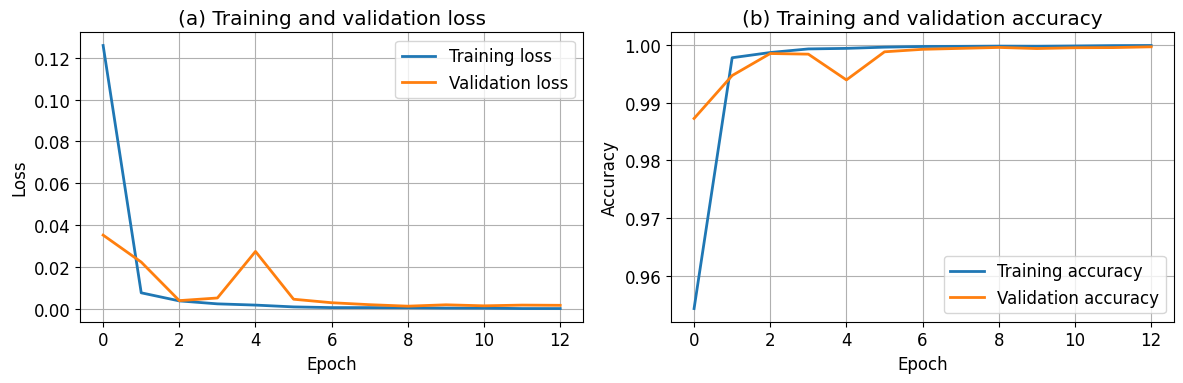

In [ ]:
import matplotlib.pyplot as plt

history = history_v3c_temporal.history

fig, axes = plt.subplots(1, 2, figsize=(12,4))


# -----------------------------
# (a) Loss
# -----------------------------
axes[0].plot(
    history['loss'],
    label='Training loss',
    linewidth=2
)

axes[0].plot(
    history['val_loss'],
    label='Validation loss',
    linewidth=2
)

axes[0].set_title('(a) Training and validation loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True)


# -----------------------------
# (b) Accuracy
# -----------------------------
axes[1].plot(
    history['accuracy'],
    label='Training accuracy',
    linewidth=2
)

axes[1].plot(
    history['val_accuracy'],
    label='Validation accuracy',
    linewidth=2
)

axes[1].set_title('(b) Training and validation accuracy')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(True)


plt.tight_layout()


plt.savefig(
    "CNN_LSTM_training_convergence.png",
    dpi=300,
    bbox_inches='tight'
)


plt.show()

..................

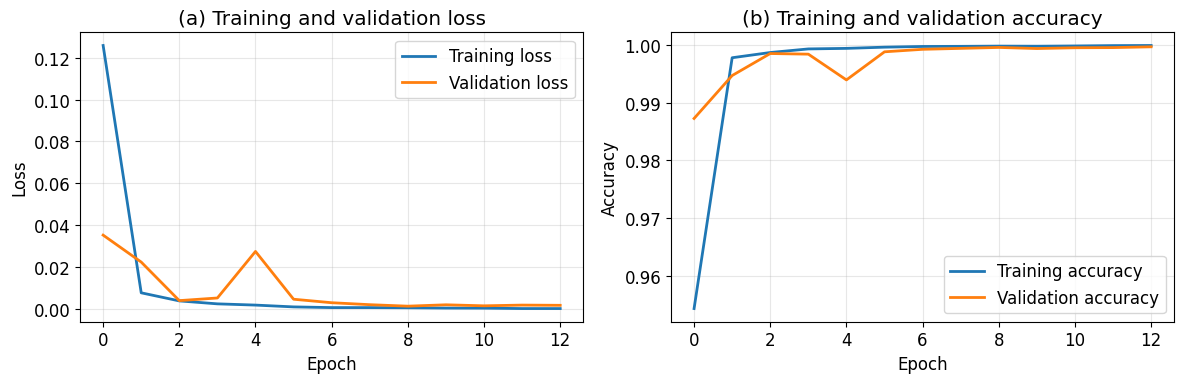

In [ ]:
import matplotlib.pyplot as plt

plt.rcParams.update({
    'font.size': 12
})


history = history_v3c_temporal.history


fig, axes = plt.subplots(
    1,2,
    figsize=(12,4)
)


# Loss
axes[0].plot(
    history['loss'],
    label='Training loss',
    linewidth=2
)

axes[0].plot(
    history['val_loss'],
    label='Validation loss',
    linewidth=2
)

axes[0].set_title(
    '(a) Training and validation loss'
)

axes[0].set_xlabel(
    'Epoch'
)

axes[0].set_ylabel(
    'Loss'
)

axes[0].legend()

axes[0].grid(alpha=0.3)



# Accuracy

axes[1].plot(
    history['accuracy'],
    label='Training accuracy',
    linewidth=2
)

axes[1].plot(
    history['val_accuracy'],
    label='Validation accuracy',
    linewidth=2
)

axes[1].set_title(
    '(b) Training and validation accuracy'
)

axes[1].set_xlabel(
    'Epoch'
)

axes[1].set_ylabel(
    'Accuracy'
)

axes[1].legend()

axes[1].grid(alpha=0.3)



plt.tight_layout()


plt.savefig(
    "Figure_training_convergence.pdf",
    bbox_inches='tight'
)


plt.savefig(
    "Figure_training_convergence.png",
    dpi=300,
    bbox_inches='tight'
)


plt.show()

**MATRIZ DE CONFUSIÓN DEL MODELO CNN-LSTM TEMPORAL**

1442/1442 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step


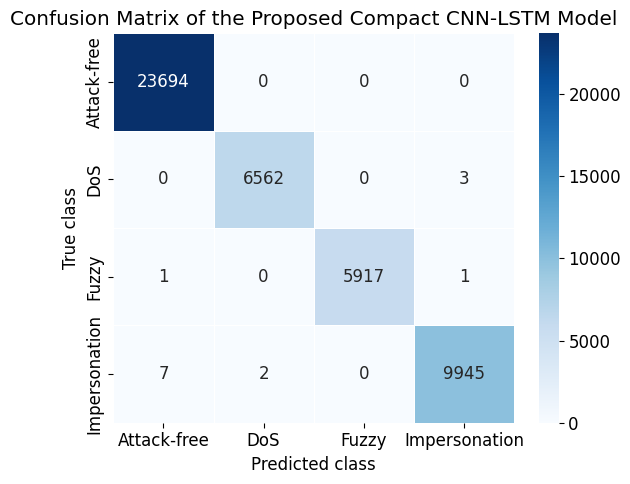

               precision    recall  f1-score   support

  Attack-free     0.9997    1.0000    0.9998     23694
          DoS     0.9997    0.9995    0.9996      6565
        Fuzzy     1.0000    0.9997    0.9998      5919
Impersonation     0.9996    0.9991    0.9993      9954

     accuracy                         0.9997     46132
    macro avg     0.9997    0.9996    0.9997     46132
 weighted avg     0.9997    0.9997    0.9997     46132



In [ ]:
# ============================================================
# MATRIZ DE CONFUSIÓN DEL MODELO CNN-LSTM TEMPORAL
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix, classification_report


# 1. Generar predicciones del modelo CNN-LSTM
y_pred_prob = model_v3c_temporal.predict(X_temporal_test)

# Convertir probabilidades a clases
y_pred_classes = np.argmax(y_pred_prob, axis=1)


# 2. Convertir etiquetas reales si están codificadas one-hot
if len(y_temporal_test.shape) > 1:
    y_true_classes = np.argmax(y_temporal_test, axis=1)
else:
    y_true_classes = y_temporal_test


# 3. Definir nombres de clases
class_names = [
    "Attack-free",
    "DoS",
    "Fuzzy",
    "Impersonation"
]


# 4. Calcular matriz de confusión
cm = confusion_matrix(
    y_true_classes,
    y_pred_classes
)


# 5. Visualización estilo artículo IEEE
plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    linewidths=0.5,
    cbar=True
)

plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.title("Confusion Matrix of the Proposed Compact CNN-LSTM Model")

plt.tight_layout()

plt.show()


# 6. Reporte de clasificación
print(
    classification_report(
        y_true_classes,
        y_pred_classes,
        target_names=class_names,
        digits=4
    )
)

**FPR & FNR COMPARISON - CNN-LSTM**

In [ ]:
from sklearn.metrics import confusion_matrix
import numpy as np

cm_fpr = confusion_matrix(y_temporal_test, temporal_pred, labels=[0, 1, 2, 3])
TP = np.diag(cm_fpr)
FP = cm_fpr.sum(axis=0) - TP
FN = cm_fpr.sum(axis=1) - TP
TN = cm_fpr.sum() - (TP + FP + FN)

fpr_mean = np.mean(FP / (FP + TN))   # macro one-vs-rest FPR
fnr_mean = np.mean(FN / (FN + TP))   # macro FNR = 1 - macro recall
print(f"FPR = {fpr_mean:.6e}   FNR = {fnr_mean:.6e}")

FPR = 1.294124e-04   FNR = 4.247557e-04


Valores usados: [np.float64(0.00012941240510942368), np.float64(0.0004247557051223061)]


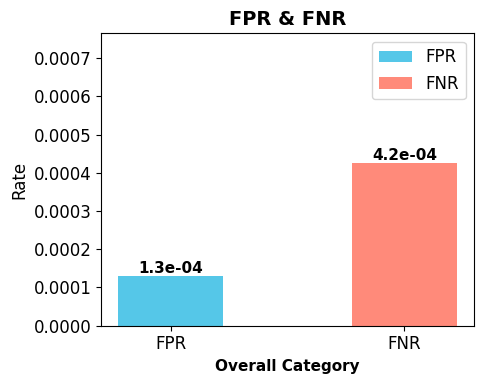

In [ ]:
import matplotlib.pyplot as plt


# Coloca directamente tus valores calculados
fpr_value = fpr_mean
fnr_value = fnr_mean


labels = ["FPR", "FNR"]
values = [fpr_value, fnr_value]


print("Valores usados:", values)


fig, ax = plt.subplots(figsize=(5,4))


bars = ax.bar(
    labels,
    values,
    width=0.45,
    color=["#55C7E8","#FF8A7A"]
)


# Mostrar valores encima de las barras
for bar, value in zip(bars, values):

    ax.text(
        bar.get_x() + bar.get_width()/2,
        value,
        f"{value:.1e}",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )


ax.set_title(
    "FPR & FNR",
    fontsize=14,
    fontweight="bold"
)


ax.set_ylabel("Rate")

ax.set_xlabel(
    "Overall Category",
    fontsize=11,
    fontweight="bold"
)


# Ajustar escala para valores pequeños
ax.set_ylim(
    0,
    max(values)*1.8
)


ax.legend(
    bars,
    ["FPR","FNR"],
    loc="upper right"
)


plt.tight_layout()

plt.savefig(
    "FPR_FNR_CNN_LSTM.png",
    dpi=600,
    bbox_inches="tight"
)


plt.show()

**ROC Curve - CNN-LSTM Model**

1442/1442 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step
Micro-average AUC : 1.000000
Macro OvR AUC     : 1.000000
  AUC Attack-free  : 1.000000
  AUC DoS          : 1.000000
  AUC Fuzzy        : 1.000000
  AUC Impersonation: 1.000000


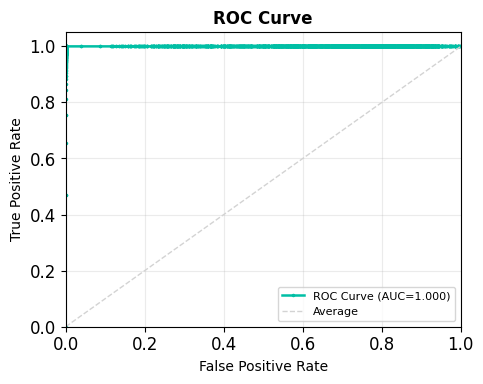

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
import numpy as np


# Predicciones probabilísticas del modelo
y_score = model_v3c_temporal.predict(X_temporal_test)


# Etiquetas reales
y_test_bin = label_binarize(
    y_temporal_test,
    classes=np.arange(4)
)


# ROC micro-average
fpr, tpr, _ = roc_curve(
    y_test_bin.ravel(),
    y_score.ravel()
)


roc_auc = auc(
    fpr,
    tpr
)

from sklearn.metrics import roc_auc_score
print(f"Micro-average AUC : {roc_auc:.6f}")
print(f"Macro OvR AUC     : {roc_auc_score(y_temporal_test, y_score, multi_class='ovr', average='macro'):.6f}")
for c, name in enumerate(['Attack-free', 'DoS', 'Fuzzy', 'Impersonation']):
    print(f"  AUC {name:13s}: {roc_auc_score(y_test_bin[:, c], y_score[:, c]):.6f}")

# ==========================
# FIGURA ESTILO IEEE ACCESS
# ==========================

plt.figure(figsize=(5,4))


plt.plot(
    fpr,
    tpr,
    color="#00BFA5",
    linewidth=1.8,
    marker='.',
    markersize=3,
    label=f"ROC Curve (AUC={roc_auc:.3f})"
)


plt.plot(
    [0,1],
    [0,1],
    linestyle="--",
    color="lightgray",
    linewidth=1,
    label="Average"
)


plt.xlabel(
    "False Positive Rate",
    fontsize=10
)


plt.ylabel(
    "True Positive Rate",
    fontsize=10
)


plt.title(
    "ROC Curve",
    fontsize=12,
    fontweight="bold"
)


plt.xlim([0,1])
plt.ylim([0,1.05])


plt.legend(
    loc="lower right",
    fontsize=8
)


plt.grid(
    alpha=0.25
)


plt.tight_layout()


plt.savefig(
    "Figure_ROC_CNN_LSTM.png",
    dpi=600,
    bbox_inches="tight"
)


plt.show()

In [ ]:
# ============================================================
# CONTROLLED PROTOCOL COMPARISON
# FROZEN CNN-LSTM V3-C + RANDOM FOREST
# UNDER THE RANDOM STRATIFIED (DEVELOPMENT-STYLE) PROTOCOL
#
# Same architecture, same training configuration, same RF.
# Only the data-partitioning protocol changes.
# Requires: cells 1-10 already executed (df_clean, build_temporal_windows).
# Does NOT overwrite any temporal variable or temporal evidence file.
# ============================================================

import os, json, random
import numpy as np
import tensorflow as tf
from time import perf_counter
from scipy.stats import binomtest
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (Input, Conv1D, BatchNormalization, Activation, MaxPooling1D,
                                     SpatialDropout1D, LSTM, Dropout, Dense)

SEED = 42

# ------------------------------------------------------------
# 1. NON-OVERLAPPING WINDOWS OVER THE COMPLETE VALIDATED CORPUS
#    (built independently inside each OTIDS source file)
# ------------------------------------------------------------
X_rand_raw, y_rand_all, _ = build_temporal_windows(df_clean, "RANDOM PROTOCOL - ALL MESSAGES")
assert X_rand_raw.shape[0] == 230669, X_rand_raw.shape

# ------------------------------------------------------------
# 2. RANDOM STRATIFIED SPLIT 64 / 16 / 20 (seed 42)
# ------------------------------------------------------------
X_tmp, X_rand_test_raw, y_tmp, y_rand_test = train_test_split(
    X_rand_raw, y_rand_all, test_size=0.20, stratify=y_rand_all, random_state=SEED)
X_rand_train_raw, X_rand_val_raw, y_rand_train, y_rand_val = train_test_split(
    X_tmp, y_tmp, test_size=0.20, stratify=y_tmp, random_state=SEED)

print("Random train:", X_rand_train_raw.shape[0], "| val:", X_rand_val_raw.shape[0],
      "| test:", X_rand_test_raw.shape[0])
assert (X_rand_train_raw.shape[0], X_rand_val_raw.shape[0], X_rand_test_raw.shape[0]) == (147628, 36907, 46134)

# ------------------------------------------------------------
# 3. MIN-MAX SCALER FITTED ONLY ON THE RANDOM TRAINING PARTITION
# ------------------------------------------------------------
scaler_rand = MinMaxScaler().fit(X_rand_train_raw.reshape(-1, 10))
scale = lambda X: scaler_rand.transform(X.reshape(-1, 10)).reshape(X.shape).astype(np.float32)
X_rand_train, X_rand_val, X_rand_test = scale(X_rand_train_raw), scale(X_rand_val_raw), scale(X_rand_test_raw)

# ------------------------------------------------------------
# 4. FROZEN V3-C ARCHITECTURE, NEW WEIGHTS (identical to cell 12)
# ------------------------------------------------------------
tf.keras.backend.clear_session()
random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)
try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    pass

model_v3c_random = Sequential([
    Input(shape=(20, 10)),
    Conv1D(64, 3, padding="same", use_bias=False), BatchNormalization(), Activation("relu"),
    Conv1D(128, 3, padding="same", use_bias=False), BatchNormalization(), Activation("relu"),
    MaxPooling1D(pool_size=2),
    SpatialDropout1D(0.10),
    LSTM(32, return_sequences=False),
    Dropout(0.20),
    Dense(32, activation="relu"),
    Dropout(0.10),
    Dense(4, activation="softmax"),
])
assert model_v3c_random.count_params() == 49060

model_v3c_random.compile(
    optimizer=tf.keras.optimizers.AdamW(learning_rate=3e-4, weight_decay=1e-4),
    loss="sparse_categorical_crossentropy", metrics=["accuracy"])

callbacks_rand = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True, verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6, verbose=1),
]

# ------------------------------------------------------------
# 5. TRAIN CNN-LSTM (random test set is NOT used)
# ------------------------------------------------------------
t0 = perf_counter()
hist_rand = model_v3c_random.fit(X_rand_train, y_rand_train,
                                 validation_data=(X_rand_val, y_rand_val),
                                 epochs=30, batch_size=64, callbacks=callbacks_rand, verbose=1)
cnn_rand_train_time = perf_counter() - t0
cnn_rand_pred = np.argmax(model_v3c_random.predict(X_rand_test, batch_size=64, verbose=0), axis=1)

# ------------------------------------------------------------
# 6. RANDOM FOREST - same configuration as the temporal experiment
# ------------------------------------------------------------
rf_random = RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1)
t0 = perf_counter()
rf_random.fit(X_rand_train.reshape(len(X_rand_train), -1), y_rand_train)
rf_rand_train_time = perf_counter() - t0
rf_rand_pred = rf_random.predict(X_rand_test.reshape(len(X_rand_test), -1))

# ------------------------------------------------------------
# 7. METRICS + EXACT McNEMAR
# ------------------------------------------------------------
def metrics(y, p):
    return {
        "accuracy": 100 * accuracy_score(y, p),
        "macro_precision": 100 * precision_score(y, p, average="macro", zero_division=0),
        "macro_recall": 100 * recall_score(y, p, average="macro", zero_division=0),
        "macro_f1": 100 * f1_score(y, p, average="macro", zero_division=0),
        "weighted_f1": 100 * f1_score(y, p, average="weighted", zero_division=0),
        "errors": int(np.sum(y != p)),
    }

def mcnemar(y, p_cnn, p_rf):
    c_ok, r_ok = (p_cnn == y), (p_rf == y)
    b, c = int(np.sum(c_ok & ~r_ok)), int(np.sum(~c_ok & r_ok))
    return {"both_correct": int(np.sum(c_ok & r_ok)), "cnn_correct_rf_wrong": b,
            "cnn_wrong_rf_correct": c, "both_wrong": int(np.sum(~c_ok & ~r_ok)),
            "exact_p_value": float(binomtest(min(b, c), b + c, 0.5).pvalue) if b + c > 0 else 1.0}

results = {
    "random_stratified": {
        "test_sequences": int(len(y_rand_test)),
        "epochs_executed": len(hist_rand.history["loss"]),
        "cnn_lstm_v3c": {**metrics(y_rand_test, cnn_rand_pred), "training_time_s": cnn_rand_train_time},
        "random_forest": {**metrics(y_rand_test, rf_rand_pred), "training_time_s": rf_rand_train_time},
        "mcnemar": mcnemar(y_rand_test, cnn_rand_pred, rf_rand_pred),
        "cnn_confusion_matrix": confusion_matrix(y_rand_test, cnn_rand_pred, labels=[0, 1, 2, 3]).tolist(),
        "rf_confusion_matrix": confusion_matrix(y_rand_test, rf_rand_pred, labels=[0, 1, 2, 3]).tolist(),
    }
}
if "temporal_pred" in globals() and "rf_temporal_pred" in globals():
    results["chronological_hold_out"] = {
        "test_sequences": int(len(y_temporal_test)),
        "cnn_lstm_v3c": metrics(y_temporal_test, temporal_pred),
        "random_forest": metrics(y_temporal_test, rf_temporal_pred),
        "mcnemar": mcnemar(y_temporal_test, temporal_pred, rf_temporal_pred),
    }

# ------------------------------------------------------------
# 8. PRINT 2 x 2 SUMMARY
# ------------------------------------------------------------
print("\n" + "=" * 100)
print("CONTROLLED PROTOCOL COMPARISON - FROZEN V3-C vs RANDOM FOREST")
print("=" * 100)
print(f"{'Protocol':<24}{'Model':<16}{'Acc (%)':>11}{'MacroP (%)':>12}{'MacroR (%)':>12}"
      f"{'MacroF1 (%)':>13}{'WF1 (%)':>11}{'Errors':>8}")
for proto in results:
    for key, name in (("cnn_lstm_v3c", "CNN-LSTM V3-C"), ("random_forest", "Random Forest")):
        m = results[proto][key]
        print(f"{proto:<24}{name:<16}{m['accuracy']:>11.6f}{m['macro_precision']:>12.6f}"
              f"{m['macro_recall']:>12.6f}{m['macro_f1']:>13.6f}{m['weighted_f1']:>11.6f}{m['errors']:>8}")
print("\nEXACT McNEMAR (two-sided)")
for proto in results:
    mc = results[proto]["mcnemar"]
    print(f"{proto:<24} b (CNN ok/RF wrong) = {mc['cnn_correct_rf_wrong']:>3} | "
          f"c (CNN wrong/RF ok) = {mc['cnn_wrong_rf_correct']:>3} | p = {mc['exact_p_value']:.6e}")
print(f"\nCNN-LSTM epochs (random protocol): {results['random_stratified']['epochs_executed']}")
print("Check vs. earlier development run: Random Forest random-split errors were 10.")

# ------------------------------------------------------------
# 9. SAVE EVIDENCE IN A NEW FOLDER (temporal evidence untouched)
# ------------------------------------------------------------
RANDOM_DIR = "/content/drive/MyDrive/CAN_IDS_FINAL_EVIDENCE/RANDOM_PROTOCOL_V3C"
os.makedirs(RANDOM_DIR, exist_ok=True)
with open(os.path.join(RANDOM_DIR, "random_vs_temporal_v3c_rf.json"), "w") as f:
    json.dump(results, f, indent=2)
model_v3c_random.save(os.path.join(RANDOM_DIR, "cnn_lstm_v3c_random.keras"))
print("\nSaved to:", RANDOM_DIR)


RANDOM PROTOCOL - ALL MESSAGES
Attack_free_dataset.txt: 2,369,398 messages -> 118,469 windows | remainder = 18
DoS_attack_dataset.txt: 656,579 messages -> 32,828 windows | remainder = 19
Fuzzy_attack_dataset.txt: 591,988 messages -> 29,599 windows | remainder = 8
Impersonation_attack_dataset.txt: 995,472 messages -> 49,773 windows | remainder = 12

----------------------------------------------
X: (230669, 20, 10)
y: (230669,)
ts: (230669,)
Residual messages: 57
Random train: 147628 | val: 36907 | test: 46134
Epoch 1/30
2307/2307 ━━━━━━━━━━━━━━━━━━━━ 59s 24ms/step - accuracy: 0.9517 - loss: 0.1310 - val_accuracy: 0.9983 - val_loss: 0.0062 - learning_rate: 3.0000e-04
Epoch 2/30
2307/2307 ━━━━━━━━━━━━━━━━━━━━ 53s 23ms/step - accuracy: 0.9975 - loss: 0.0083 - val_accuracy: 0.9993 - val_loss: 0.0024 - learning_rate: 3.0000e-04
Epoch 3/30
2307/2307 ━━━━━━━━━━━━━━━━━━━━ 55s 24ms/step - accuracy: 0.9989 - loss: 0.0037 - val_accuracy: 0.9990 - val_loss: 0.0035 - learning_rate: 3.0000e-04
Epoc